# Sparse pairwise regression with MGS-KAN

At a matched trainable parameter budget, does a standalone MGS-KAN predict a scalar function with sparse pairwise interactions more accurately than a two-hidden-layer MLP? Held-out RMSE measures prediction. Ranks and threshold crossings of learned pair terms measure interaction recovery.

From the repository root, use Python 3.12, then run:

```bash
python -m pip install -r requirements-study.txt
python -m jupyterlab study.ipynb
```

Select the environment's Python kernel and choose **Restart Kernel and Run All Cells**. To run headlessly and save the outputs in this notebook:

```bash
python -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 study.ipynb
```

Runs are saved under `outputs/study/`, in a subdirectory keyed by the frozen code, settings and runtime. Run this notebook again to verify and reuse completed fits after an interruption. Set `output_root` to a new directory before running all cells for a fully fresh repeat.

The first study is followed by an independent extension with 10 new data seeds and a second sparse target. On the recorded runtime, the notebook reads and verifies the saved first study without writing to its folder. The extension stores its own protocol, tuning and fits under `outputs/study/followup/`. A clean checkout without the original artifacts regenerates the first study before the extension.


## 1. Freeze the protocol and target calibration

Each feature is drawn independently from $N(0,1)$. In the additive control the three components are $\sin(x_6)$, $0.5(x_7^2-1)$ and $\tanh(x_8)$. The sparse task adds $x_0x_1$, $\sin(x_2x_3)$ and a rotated Gaussian on $(x_4,x_5)$. Indices start at zero. Each component is centered and scaled to unit variance before summation. Each summed signal is centered and scaled again. All these constants come from a separate, fixed sample of 100,000 inputs. Independent noise with SD 0.1 is added afterward. Within a data seed, both tasks share the raw inputs, split rows and noise. Models receive only standardized inputs and observed targets. Input scaling uses training rows only.

The standalone model sums an affine term, four learned Gaussian kernels per feature and two per pair. For each of the 66 pairs, each kernel has the form $a\exp[-\tfrac12 (x-\mu)^\top LL^\top(x-\mu)]$, with its own learned amplitude, center and lower triangular factor. Diagonal entries are exponentials of free parameters. Univariate precision is the square of an exponentiated parameter. Training minimizes MSE plus $\lambda\sum_{i<j}\|a_{ij}\|_2$. The MLP uses two width-24 ReLU layers and a linear output.

The earlier repository draft supplied seed lists and initialization conventions. The scalar-regression proposal's numerical Gaussian constants were unavailable. This study uses the **substitute fixture** with center $(0.3,-0.4)$, amplitude $1.7$, principal-axis rotation $\pi/6$ counterclockwise, and precision eigenvalues $(4,0.5)$. The generator uses the same shape.

In [1]:
from pathlib import Path
from time import perf_counter

import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from src import config as c
from src.experiment import (
    DEFAULT_OUTPUT, freeze_protocol, numerical_checks, original_archive, paired_results,
    run_final, run_pilot, tune, verify_final,
)

def table(headers, rows):
    lines = [headers, ["---"] * len(headers), *rows]
    display(Markdown("\n".join("| " + " | ".join(map(str, line)) + " |" for line in lines)))

started = perf_counter()
output_root = DEFAULT_OUTPUT
archive = original_archive(output_root)
output, protocol = archive if archive else freeze_protocol(output_root)
print(f"Original protocol and reference constants in {output / 'protocol.json'}")
print(protocol["settings"]["runtime"])
print(f"Training / validation / test sizes {c.SPLIT_SIZES}")
print(f"Final data seeds {c.DATA_SEEDS} • initialization seeds {c.INIT_SEEDS}")
print(f"Pair cutoff {c.SELECTION_FRACTION:.0%} of noisy training-target SD, in target units")

Original protocol and reference constants in outputs/study/df24c2b5a1de3a48/protocol.json
{'torch': '2.15.0+cu132', 'numpy': '2.5.4', 'python': '3.12.16', 'platform': 'Linux-6.18.63-3-lts-x86_64-with-glibc2.44', 'device': 'cpu', 'cpu': 'Intel(R) Core(TM) i5-9400F CPU @ 2.90GHz'}
Training / validation / test sizes (2048, 512, 2048)
Final data seeds (2311, 2411, 2511) • initialization seeds (71, 73, 79)
Pair cutoff 5% of noisy training-target SD, in target units


## 2. Verify the model and the interaction calculation

Float64 checks cover the exact pair list, prediction decomposition, positive definiteness, finite-difference agreement for inputs and trainable parameters, and the rotated kernel against independent principal-coordinate evaluation. Off-axis probes exercise the cross term. The same Cartesian centering code used for scoring is checked against a purely additive surface and a product.

In [2]:
checks = json.loads((output / "checks.json").read_text()) if archive else numerical_checks(output)
table(["Check", "Result"], [(k.replace("_", " "), v) for k, v in checks.items()])

| Check | Result |
| --- | --- |
| status | passed |
| dtype | float64 |
| candidate pairs | 66 |
| parameter counts | {'mgs_kan': 949, 'mlp': 937} |
| relative parameter gap | 0.012644889357218124 |
| minimum precision eigenvalue | 0.6395241187411125 |
| gradcheck | passed |
| substitute gaussian max abs error | 2.7755575615628914e-16 |
| additive max abs error | 4.440892098500626e-16 |
| product max abs error | 1.1102230246251565e-16 |

## 3. Noiseless overfit pilot

Fit each model to the same 32 noiseless rows on each task, with no regularization and a finite 350-epoch budget. Training RMSE must be below 0.05 reference signal SD on all four fits to proceed.

In [3]:
pilot = json.loads((output / "pilot" / "results.json").read_text()) if archive else run_pilot(output, protocol)
table(["Task", "Model", "Training RMSE", "Selected epoch"],
      [(r["task"], r["model"], f"{r['training_rmse']:.3g}", r["epoch"]) for r in pilot])

| Task | Model | Training RMSE | Selected epoch |
| --- | --- | --- | --- |
| sparse | mgs_kan | 9.21e-08 | 349 |
| sparse | mlp | 5.3e-08 | 308 |
| additive | mgs_kan | 4.13e-08 | 342 |
| additive | mlp | 4.41e-08 | 316 |

## 4. Tune on development data and freeze the winners

Each task and model receives four Adam trials on the dedicated development split. The grid crosses learning rates 0.001 and 0.003 with group penalties 0.0001 and 0.001 for MGS-KAN or weight decay 0 and 0.001 for the MLP. Both models use batch size 128, at most 300 epochs, validation each epoch and patience 30. Tied epochs favor the earlier checkpoint. Tied trials favor the first grid entry. Selection uses observed validation RMSE independently for each task and model. The development seed and initialization are separate from the pilot and final seeds.

In [4]:
development = (json.loads((output / "tuning" / "selection.json").read_text())
               if archive else tune(output, protocol))
table(["Task", "Model", "Trial", "Learning rate", "Penalty or decay", "Best epoch", "Validation RMSE", "Selected"],
      [(r["task"], r["model"], r["trial"], r["settings"]["lr"], r["settings"]["regularization"],
        r["best_epoch"], f"{r['validation_rmse']:.5f}", "Yes" if r["selected"] else "")
       for r in development["trials"]])
print(f"Frozen winners saved to {output / 'tuning' / 'selection.json'}")

| Task | Model | Trial | Learning rate | Penalty or decay | Best epoch | Validation RMSE | Selected |
| --- | --- | --- | --- | --- | --- | --- | --- |
| sparse | mgs_kan | 1 | 0.001 | 0.0001 | 296 | 0.28499 |  |
| sparse | mgs_kan | 2 | 0.001 | 0.001 | 298 | 0.28289 |  |
| sparse | mgs_kan | 3 | 0.003 | 0.0001 | 298 | 0.25396 |  |
| sparse | mgs_kan | 4 | 0.003 | 0.001 | 300 | 0.24731 | Yes |
| sparse | mlp | 1 | 0.001 | 0.0 | 288 | 0.35970 |  |
| sparse | mlp | 2 | 0.001 | 0.001 | 295 | 0.34284 |  |
| sparse | mlp | 3 | 0.003 | 0.0 | 118 | 0.36632 |  |
| sparse | mlp | 4 | 0.003 | 0.001 | 203 | 0.33778 | Yes |
| additive | mgs_kan | 1 | 0.001 | 0.0001 | 297 | 0.12865 |  |
| additive | mgs_kan | 2 | 0.001 | 0.001 | 296 | 0.12612 |  |
| additive | mgs_kan | 3 | 0.003 | 0.0001 | 295 | 0.12004 |  |
| additive | mgs_kan | 4 | 0.003 | 0.001 | 300 | 0.11533 | Yes |
| additive | mlp | 1 | 0.001 | 0.0 | 242 | 0.12871 |  |
| additive | mlp | 2 | 0.001 | 0.001 | 298 | 0.12611 | Yes |
| additive | mlp | 3 | 0.003 | 0.0 | 87 | 0.13450 |  |
| additive | mlp | 4 | 0.003 | 0.001 | 156 | 0.12891 |  |

Frozen winners saved to outputs/study/df24c2b5a1de3a48/tuning/selection.json


## 5. Run 36 final fits and verify the saved evidence

For each task, the two models share each of the three data splits. In each split, three initialization seeds give three paired minibatch orders. The best validation checkpoint is selected before the test set is scored. Each final bundle contains the fit identifiers, frozen protocol ID, selected settings, checkpoint, validation history, and observed targets and predictions in test-row order. MGS-KAN bundles also contain all 66 scored pairs.

Verification reloads every checkpoint, checks validation selection, regenerates the held-out rows, compares predictions to a fresh checkpoint evaluation and recomputes test RMSE. Reporting requires all 36 distinct fit keys.

In [5]:
if archive:
    print("Original fits located. The next cell verifies the archive read-only.")
else:
    run_final(output, protocol, development["selected"])

Original fits located. The next cell verifies the archive read-only.


In [6]:
fits, recovery, variances = verify_final(output, protocol, archived=archive is not None)
paired = paired_results(fits)
print(f"Verified {len(fits)} distinct fit keys, checkpoints and saved test RMSEs.")
print(f"Original manifest in {output / 'final' / 'manifest.json'}")
if archive:
    print("Verified the original archive. Its recorded fit times appear below.")
else:
    print(f"Wall time through final verification {(perf_counter() - started) / 60:.2f} min.")

Verified 36 distinct fit keys, checkpoints and saved test RMSEs.
Original manifest in outputs/study/df24c2b5a1de3a48/final/manifest.json
Verified the original archive. Its recorded fit times appear below.


### Generator checks on final splits

Noiseless target and noise variances are shown for each split. Signal and noise variances should be near 1 and 0.01, respectively, with sampling variation. These measurements are for evaluation only.

In [7]:
table(["Task", "Data seed", "Split", "Signal variance", "Noise variance"],
      [(r["task"], r["data_seed"], r["split"], f"{r['signal_variance']:.4f}", f"{r['noise_variance']:.5f}")
       for r in variances])

| Task | Data seed | Split | Signal variance | Noise variance |
| --- | --- | --- | --- | --- |
| sparse | 2311 | train | 1.0486 | 0.01000 |
| sparse | 2311 | validation | 0.9327 | 0.00915 |
| sparse | 2311 | test | 1.0195 | 0.00995 |
| sparse | 2411 | train | 1.0032 | 0.01004 |
| sparse | 2411 | validation | 1.0298 | 0.00957 |
| sparse | 2411 | test | 1.0219 | 0.01002 |
| sparse | 2511 | train | 1.0683 | 0.01065 |
| sparse | 2511 | validation | 1.0225 | 0.01001 |
| sparse | 2511 | test | 0.9905 | 0.00984 |
| additive | 2311 | train | 1.0601 | 0.01000 |
| additive | 2311 | validation | 0.8915 | 0.00915 |
| additive | 2311 | test | 0.9927 | 0.00995 |
| additive | 2411 | train | 1.0095 | 0.01004 |
| additive | 2411 | validation | 1.0358 | 0.00957 |
| additive | 2411 | test | 1.0091 | 0.01002 |
| additive | 2511 | train | 0.9951 | 0.01065 |
| additive | 2511 | validation | 0.9665 | 0.01001 |
| additive | 2511 | test | 1.0181 | 0.00984 |

## 6. Held-out prediction

Each paired row averages the three initialization-level RMSEs within one data seed and then subtracts MLP from MGS-KAN. Both RMSE and the difference are in target units. Negative differences favor MGS-KAN. The three data seeds are the units of the comparison.

| Task | Data seed | MGS-KAN mean RMSE | MLP mean RMSE | MGS-KAN − MLP |
| --- | --- | --- | --- | --- |
| sparse | 2311 | 0.2313 | 0.3305 | -0.0992 |
| sparse | 2411 | 0.2292 | 0.3302 | -0.1010 |
| sparse | 2511 | 0.2398 | 0.3302 | -0.0904 |
| additive | 2311 | 0.1132 | 0.1365 | -0.0233 |
| additive | 2411 | 0.1243 | 0.1370 | -0.0127 |
| additive | 2511 | 0.1116 | 0.1426 | -0.0310 |

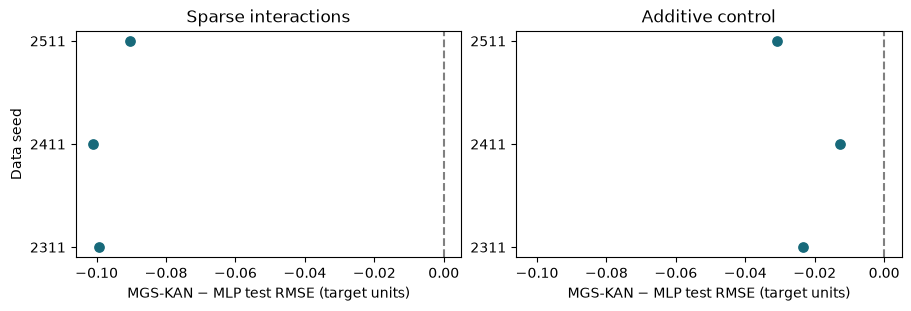

In [8]:
labels = {"sparse": "Sparse interactions", "additive": "Additive control"}
table(["Task", "Data seed", "MGS-KAN mean RMSE", "MLP mean RMSE", "MGS-KAN − MLP"],
      [(r["task"], r["data_seed"], f"{r['mgs_kan']:.4f}", f"{r['mlp']:.4f}", f"{r['difference']:+.4f}")
       for r in paired])

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharex=True, layout="constrained")
for ax, task in zip(axes, c.TASKS):
    rows = [r for r in paired if r["task"] == task]
    ax.axvline(0, color="0.5", linestyle="--")
    ax.scatter([r["difference"] for r in rows], [str(r["data_seed"]) for r in rows], color="#17697a", s=45)
    ax.set(title=labels[task], xlabel="MGS-KAN − MLP test RMSE (target units)")
axes[0].set_ylabel("Data seed")
plt.show()

In [9]:
table(["Task", "Data seed", "Init", "Model", "Best epoch", "Test RMSE", "Training seconds"],
      [(r["task"], r["data_seed"], r["init_seed"], r["model"], r["best_epoch"],
        f"{r['test_rmse']:.5f}", f"{r['training_seconds']:.2f}") for r in fits])

| Task | Data seed | Init | Model | Best epoch | Test RMSE | Training seconds |
| --- | --- | --- | --- | --- | --- | --- |
| sparse | 2311 | 71 | mgs_kan | 297 | 0.23247 | 8.67 |
| sparse | 2311 | 71 | mlp | 152 | 0.34534 | 2.19 |
| sparse | 2311 | 73 | mgs_kan | 300 | 0.23389 | 8.69 |
| sparse | 2311 | 73 | mlp | 293 | 0.32164 | 3.70 |
| sparse | 2311 | 79 | mgs_kan | 300 | 0.22756 | 8.54 |
| sparse | 2311 | 79 | mlp | 217 | 0.32462 | 2.99 |
| sparse | 2411 | 71 | mgs_kan | 299 | 0.23578 | 8.57 |
| sparse | 2411 | 71 | mlp | 180 | 0.32187 | 2.53 |
| sparse | 2411 | 73 | mgs_kan | 297 | 0.22588 | 8.91 |
| sparse | 2411 | 73 | mlp | 112 | 0.35162 | 1.79 |
| sparse | 2411 | 79 | mgs_kan | 300 | 0.22599 | 8.36 |
| sparse | 2411 | 79 | mlp | 290 | 0.31714 | 3.55 |
| sparse | 2511 | 71 | mgs_kan | 298 | 0.24400 | 8.58 |
| sparse | 2511 | 71 | mlp | 297 | 0.31332 | 3.52 |
| sparse | 2511 | 73 | mgs_kan | 295 | 0.22578 | 8.71 |
| sparse | 2511 | 73 | mlp | 232 | 0.34334 | 3.21 |
| sparse | 2511 | 79 | mgs_kan | 298 | 0.24965 | 8.93 |
| sparse | 2511 | 79 | mlp | 188 | 0.33397 | 2.64 |
| additive | 2311 | 71 | mgs_kan | 232 | 0.11253 | 7.42 |
| additive | 2311 | 71 | mlp | 300 | 0.13883 | 3.60 |
| additive | 2311 | 73 | mgs_kan | 229 | 0.11250 | 8.34 |
| additive | 2311 | 73 | mlp | 297 | 0.12832 | 4.53 |
| additive | 2311 | 79 | mgs_kan | 275 | 0.11451 | 8.08 |
| additive | 2311 | 79 | mlp | 294 | 0.14220 | 3.53 |
| additive | 2411 | 71 | mgs_kan | 227 | 0.12343 | 7.14 |
| additive | 2411 | 71 | mlp | 286 | 0.13564 | 3.55 |
| additive | 2411 | 73 | mgs_kan | 241 | 0.12514 | 7.52 |
| additive | 2411 | 73 | mlp | 289 | 0.13771 | 3.53 |
| additive | 2411 | 79 | mgs_kan | 290 | 0.12422 | 8.36 |
| additive | 2411 | 79 | mlp | 259 | 0.13758 | 3.41 |
| additive | 2511 | 71 | mgs_kan | 297 | 0.11085 | 8.34 |
| additive | 2511 | 71 | mlp | 294 | 0.13990 | 3.43 |
| additive | 2511 | 73 | mgs_kan | 282 | 0.11139 | 8.38 |
| additive | 2511 | 73 | mlp | 230 | 0.14690 | 3.47 |
| additive | 2511 | 79 | mgs_kan | 297 | 0.11261 | 8.62 |
| additive | 2511 | 79 | mlp | 297 | 0.14102 | 3.42 |

## 7. Interaction recovery

For a learned pair function $g$, evaluate $G_{rs}=g(u_r,v_s)$ on the full Cartesian product of its two empirical validation marginals in standardized model-input coordinates. Subtract each row mean and each column mean and add the grand mean. This removes the constant and both marginal main effects. The score is the RMS of the double-centered diagonal, in target units. Ranking uses descending scores and lexicographic ties. Selection requires a score **strictly greater** than 0.05 times the SD of the observed training target. This effect-size rule was frozen before tuning.

The sparse table reports planted-pair ranks and top-three hits. Every threshold crossing in the additive control is a false selection.

| Data seed | Init | Rank (0, 1) | Rank (2, 3) | Rank (4, 5) | Top-three hits | Selected of 66 | Cutoff (target units) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 2311 | 71 | 2 | 1 | 3 | 3 | 3 | 0.05144 |
| 2311 | 73 | 2 | 1 | 3 | 3 | 3 | 0.05144 |
| 2311 | 79 | 2 | 1 | 3 | 3 | 3 | 0.05144 |
| 2411 | 71 | 2 | 1 | 3 | 3 | 3 | 0.05044 |
| 2411 | 73 | 2 | 1 | 3 | 3 | 3 | 0.05044 |
| 2411 | 79 | 2 | 1 | 3 | 3 | 3 | 0.05044 |
| 2511 | 71 | 1 | 2 | 3 | 3 | 3 | 0.05171 |
| 2511 | 73 | 1 | 2 | 3 | 3 | 3 | 0.05171 |
| 2511 | 79 | 1 | 2 | 3 | 3 | 3 | 0.05171 |

| Data seed | Init | False selections of 66 | Cutoff (target units) |
| --- | --- | --- | --- |
| 2311 | 71 | 0 | 0.05180 |
| 2311 | 73 | 0 | 0.05180 |
| 2311 | 79 | 0 | 0.05180 |
| 2411 | 71 | 0 | 0.05055 |
| 2411 | 73 | 0 | 0.05055 |
| 2411 | 79 | 0 | 0.05055 |
| 2511 | 71 | 0 | 0.05005 |
| 2511 | 73 | 0 | 0.05005 |
| 2511 | 79 | 0 | 0.05005 |

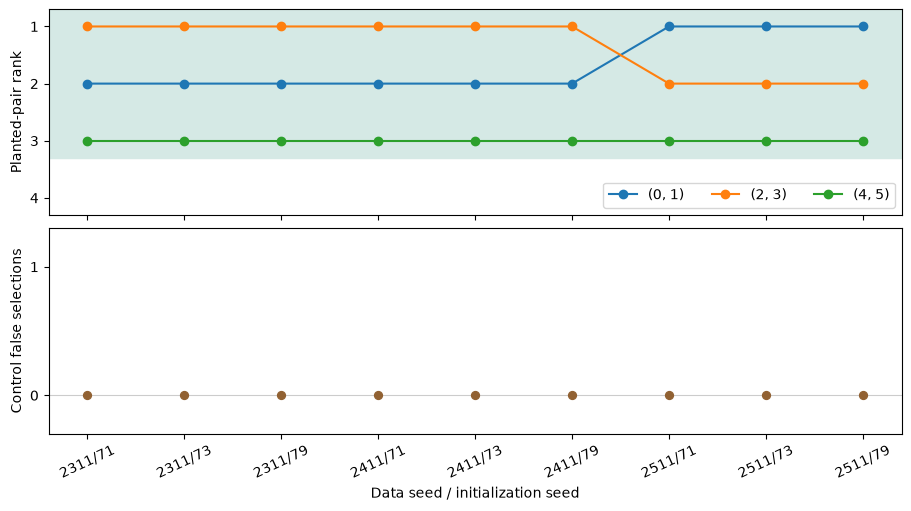

In [10]:
from matplotlib.ticker import MaxNLocator

sparse = [r for r in recovery if r["task"] == "sparse"]
control = [r for r in recovery if r["task"] == "additive"]
pairs = tuple(sparse[0]["ranks"])
table(["Data seed", "Init", *(f"Rank {pair}" for pair in pairs), "Top-three hits",
       "Selected of 66", "Cutoff (target units)"],
      [(r["data_seed"], r["init_seed"], *(r["ranks"][p] for p in pairs), r["top_three_hits"],
        r["selected"], f"{r['threshold']:.5f}") for r in sparse])
table(["Data seed", "Init", "False selections of 66", "Cutoff (target units)"],
      [(r["data_seed"], r["init_seed"], r["selected"], f"{r['threshold']:.5f}") for r in control])

fig, (ax, ctrl) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, layout="constrained")
positions = np.arange(len(sparse))
for pair in pairs:
    ax.plot(positions, [r["ranks"][pair] for r in sparse], "o-", label=str(pair))
ax.axhspan(0.7, 3.3, color="#d5e9e5", zorder=0)
ax.set_ylim(max(4, max(r["ranks"][p] for r in sparse for p in pairs)) + 0.3, 0.7)
ax.set_ylabel("Planted-pair rank")
ax.legend(ncol=3, loc="lower right")
ctrl.axhline(0, color="0.8", linewidth=0.8)
ctrl.scatter(positions, [r["selected"] for r in control], color="#916132", s=32, zorder=3)
ctrl.set_ylim(-0.3, max(1, max(r["selected"] for r in control)) + 0.3)
ctrl.yaxis.set_major_locator(MaxNLocator(integer=True))
ctrl.set_ylabel("Control false selections")
ctrl.set_xticks(positions, [f"{r['data_seed']}/{r['init_seed']}" for r in sparse], rotation=25)
ctrl.set_xlabel("Data seed / initialization seed")
plt.show()

## 8. Parameter budget and training cost

Times cover optimization, validation and restoring the chosen checkpoint. Checkpoint I/O, interaction scoring and test evaluation are outside the timed interval. Times are from the saved final fits on the recorded CPU with one PyTorch thread.

In [11]:
table(["Model", "Trainable parameters", "Final fits", "Median seconds", "Total seconds"],
      [(model, checks["parameter_counts"][model], len(times), f"{np.median(times):.2f}", f"{sum(times):.2f}")
       for model in c.MODELS
       for times in [[r["training_seconds"] for r in fits if r["model"] == model]]])
print(f"Relative parameter gap {checks['relative_parameter_gap']:.2%}.")
print(f"Pilot training {sum(r['training_seconds'] for r in pilot):.1f} s.")
print(f"Development training {sum(r['training_seconds'] for r in development['trials']):.1f} s.")

| Model | Trainable parameters | Final fits | Median seconds | Total seconds |
| --- | --- | --- | --- | --- |
| mgs_kan | 949 | 18 | 8.46 | 150.17 |
| mlp | 937 | 18 | 3.45 | 58.59 |

Relative parameter gap 1.26%.
Pilot training 2.1 s.
Development training 91.5 s.


## 9. Original verdict

In [12]:
assert len(fits) == 36
primary = [r for r in paired if r["task"] == "sparse"]
additive = [r for r in paired if r["task"] == "additive"]

def differences(rows):
    return ", ".join(f"{r['difference']:+.4f}" for r in rows)

wins = sum(r["difference"] < 0 for r in primary)
mean_kan, mean_mlp = (np.mean([r[model] for r in primary]) for model in c.MODELS)
relative_change = (mean_kan - mean_mlp) / mean_mlp
strongest = min(primary, key=lambda r: r["difference"])
weakest = max(primary, key=lambda r: r["difference"])
full_hits = sum(r["top_three_hits"] == 3 for r in sparse)
false_positive_fits = sum(r["selected"] > 0 for r in control)
max_false = max(r["selected"] for r in control)
rank_ranges = ", ".join(
    f"{p} at ranks {min(r['ranks'][p] for r in sparse)}–{max(r['ranks'][p] for r in sparse)}"
    for p in pairs
)

if wins == 3:
    prediction = "MGS-KAN reduced primary-task test RMSE on all three data seeds."
elif wins:
    prediction = f"The prediction result varied by seed. MGS-KAN had lower primary-task RMSE on {wins} of 3 seeds."
else:
    prediction = "MGS-KAN had no primary-task RMSE wins in these three data seeds."

if full_hits == 9 and not false_positive_fits:
    recovery_conclusion = "The rank and control results support identification in this synthetic setting."
else:
    recovery_conclusion = "The rank and control results put limits on identification at the frozen cutoff."

if wins == 3:
    next_study = ("A larger experiment is warranted to test whether the prediction gain persists across more "
                  "independent splits and other planted functions.")
elif full_hits >= 8 and max_false == 0:
    next_study = ("A larger experiment is warranted to test identification across other planted functions "
                  "and determine whether the prediction differences persist with more data seeds.")
else:
    next_study = ("The current results give limited grounds for a larger benchmark of the same design. "
                  "A follow-up should test what drives errors or incorrect pair rankings across seeds.")

display(Markdown(f"""
**Prediction.** {prediction} The seed-level differences (MGS-KAN minus MLP) were
{differences(primary)} target units. Mean seed-level RMSE was {mean_kan:.4f} for MGS-KAN and {mean_mlp:.4f}
for the MLP, a relative change of {relative_change:+.1%}. The most favorable comparison for MGS-KAN was {strongest['difference']:+.4f} at seed
{strongest['data_seed']}. Its weakest comparison was {weakest['difference']:+.4f} at seed
{weakest['data_seed']}. The additive-control differences were {differences(additive)}.

**Interaction recovery.** All three planted pairs occupied the top three in {full_hits}/9 sparse fits.
Across fits the rank ranges were {rank_ranges}. Exactly three pairs crossed the cutoff in {sum(r["selected"] == 3 for r in sparse)}/9 sparse fits. The additive control had false selections in
{false_positive_fits}/9 fits, with a maximum of {max_false}/66 under the frozen cutoff.
{recovery_conclusion}

**Limitation and next experiment.** The sparse-task MGS-KAN RMSE of {mean_kan:.4f} is {mean_kan / c.NOISE_SD:.2f} times the generator noise SD of {c.NOISE_SD:.2f}, so the model still leaves substantial prediction error. Three independent data seeds give a descriptive comparison. The three initializations within each split measure sensitivity to optimization on those same rows.
{next_study}
"""))


**Prediction.** MGS-KAN reduced primary-task test RMSE on all three data seeds. The seed-level differences (MGS-KAN minus MLP) were
-0.0992, -0.1010, -0.0904 target units. Mean seed-level RMSE was 0.2334 for MGS-KAN and 0.3303
for the MLP, a relative change of -29.3%. The most favorable comparison for MGS-KAN was -0.1010 at seed
2411. Its weakest comparison was -0.0904 at seed
2511. The additive-control differences were -0.0233, -0.0127, -0.0310.

**Interaction recovery.** All three planted pairs occupied the top three in 9/9 sparse fits.
Across fits the rank ranges were (0, 1) at ranks 1–2, (2, 3) at ranks 1–2, (4, 5) at ranks 3–3. Exactly three pairs crossed the cutoff in 9/9 sparse fits. The additive control had false selections in
0/9 fits, with a maximum of 0/66 under the frozen cutoff.
The rank and control results support identification in this synthetic setting.

**Limitation and next experiment.** The sparse-task MGS-KAN RMSE of 0.2334 is 2.33 times the generator noise SD of 0.10, so the model still leaves substantial prediction error. Three independent data seeds give a descriptive comparison. The three initializations within each split measure sensitivity to optimization on those same rows.
A larger experiment is warranted to test whether the prediction gain persists across more independent splits and other planted functions.


# Follow-up on 10 new data seeds

The follow-up tests whether prediction and interaction recovery carry over to fresh data and a different sparse target. The original sparse task and additive control use their frozen development winners. The second sparse target keeps the same additive terms and plants these three interactions:

| Pair (zero-based) | Component |
| --- | --- |
| $(0,2)$ | $\tanh(x_0)\tanh(x_2)$ |
| $(1,5)$ | $\exp[-\tfrac12((x_1-x_5)/0.6)^2]$ |
| $(2,4)$ | $\sin(2x_2)\sin(2x_4)$ |

Two pair terms share $x_2$. The third component in the table also introduces sign changes along each coordinate. As before, all components receive equal weights after standardization on the fixed reference sample, the summed signal is standardized, and noise with SD 0.1 is added. The learned scorer subtracts the marginal main effects, which the ridge component may contain.

The splits, parameter budget, optimizer, stopping rule and the 5% of training-target SD interaction cutoff follow the original protocol. The 10 new data seeds are independent of the original, pilot and development seeds. Three initializations per split and two models give **180 new final fits** across the three tasks. Paired models use the same rows and minibatch orders. The same inputs and noise are reused across tasks at each data seed.

In [13]:
follow_started = perf_counter()
follow_output, follow_protocol = freeze_protocol(
    output_root / "followup", inherited_settings=development["selected"],
)
print(f"Frozen protocol {follow_output / 'protocol.json'}")
print(f"Final data seeds {c.FOLLOWUP_DATA_SEEDS}")
print(f"New-target development data seed {c.FOLLOWUP_DEV_SEED}, initialization seed {c.DEV_INIT_SEED}")
follow_checks = numerical_checks(follow_output)
print(f"Float64 checks {follow_checks['status']}. Parameters {follow_checks['parameter_counts']}.")

Frozen protocol outputs/study/followup/9c04ad7dfc77dc19/protocol.json
Final data seeds (3301, 3307, 3313, 3319, 3323, 3329, 3331, 3343, 3347, 3359)
New-target development data seed 3203, initialization seed 67


Float64 checks passed. Parameters {'mgs_kan': 949, 'mlp': 937}.


## Follow-up pilot and development

Run the 32-row noiseless overfit gate on the second sparse target. Each model then gets four development trials on the same new development split. Save the validation winners for the new target together with the inherited settings before scoring any final test splits.

In [14]:
follow_pilot = run_pilot(follow_output, follow_protocol)
table(["Task", "Model", "Noiseless training RMSE"],
      [(r["task"], r["model"], f"{r['training_rmse']:.3g}") for r in follow_pilot])

follow_development = tune(follow_output, follow_protocol)
table(["Model", "Trial", "Learning rate", "Penalty or decay", "Best epoch", "Validation RMSE", "Selected"],
      [(r["model"], r["trial"], r["settings"]["lr"], r["settings"]["regularization"],
        r["best_epoch"], f"{r['validation_rmse']:.5f}", "Yes" if r["selected"] else "")
       for r in follow_development["trials"]])

| Task | Model | Noiseless training RMSE |
| --- | --- | --- |
| sparse_overlap | mgs_kan | 7.4e-08 |
| sparse_overlap | mlp | 6.76e-08 |

sparse_overlap mgs_kan trial 1 • validation RMSE 0.29397


sparse_overlap mgs_kan trial 2 • validation RMSE 0.29192


sparse_overlap mgs_kan trial 3 • validation RMSE 0.29346


sparse_overlap mgs_kan trial 4 • validation RMSE 0.29222


sparse_overlap mlp trial 1 • validation RMSE 0.33246


sparse_overlap mlp trial 2 • validation RMSE 0.32811


sparse_overlap mlp trial 3 • validation RMSE 0.25868


sparse_overlap mlp trial 4 • validation RMSE 0.26322


| Model | Trial | Learning rate | Penalty or decay | Best epoch | Validation RMSE | Selected |
| --- | --- | --- | --- | --- | --- | --- |
| mgs_kan | 1 | 0.001 | 0.0001 | 299 | 0.29397 |  |
| mgs_kan | 2 | 0.001 | 0.001 | 298 | 0.29192 | Yes |
| mgs_kan | 3 | 0.003 | 0.0001 | 138 | 0.29346 |  |
| mgs_kan | 4 | 0.003 | 0.001 | 138 | 0.29222 |  |
| mlp | 1 | 0.001 | 0.0 | 299 | 0.33246 |  |
| mlp | 2 | 0.001 | 0.001 | 299 | 0.32811 |  |
| mlp | 3 | 0.003 | 0.0 | 275 | 0.25868 | Yes |
| mlp | 4 | 0.003 | 0.001 | 220 | 0.26322 |  |

## Follow-up final fits and verification

Independent splits can run concurrently with one PyTorch thread per worker. Completed checkpoints are verified before reuse. Reporting requires the exact fit grid and regenerated test rows. Verification reloads every checkpoint and compares saved predictions with checkpoint predictions before recomputing RMSE.

In [15]:
run_final(follow_output, follow_protocol, follow_development["selected"])
follow_fits, follow_recovery, follow_variances = verify_final(follow_output, follow_protocol)
follow_elapsed = perf_counter() - follow_started
follow_paired = paired_results(follow_fits, c.FOLLOWUP_TASKS, c.FOLLOWUP_DATA_SEEDS)
assert len(follow_fits) == 180 and len(follow_recovery) == 90 and len(follow_paired) == 30
print(f"Verified {len(follow_fits)} fits and {len(follow_recovery)} complete pair rankings.")
print(f"Fit manifest {follow_output / 'final' / 'manifest.json'}")
table(["Task", "Split", "Signal variance range", "Noise variance range"],
      [(task, split, f"{min(signal):.3f}–{max(signal):.3f}", f"{min(noise):.5f}–{max(noise):.5f}")
       for task in c.FOLLOWUP_TASKS for split in ("train", "validation", "test")
       for rows in [[r for r in follow_variances if (r["task"], r["split"]) == (task, split)]]
       for signal, noise in [([r["signal_variance"] for r in rows], [r["noise_variance"] for r in rows])]])


6/180 fits complete • sparse, seed 3307 (0/6 reused and verified)


12/180 fits complete • sparse, seed 3319 (0/6 reused and verified)


18/180 fits complete • sparse, seed 3313 (0/6 reused and verified)


24/180 fits complete • sparse, seed 3301 (0/6 reused and verified)


30/180 fits complete • sparse, seed 3323 (0/6 reused and verified)


36/180 fits complete • sparse, seed 3329 (0/6 reused and verified)


... (22 outputs left out)

174/180 fits complete • additive, seed 3343 (0/6 reused and verified)


180/180 fits complete • additive, seed 3359 (0/6 reused and verified)


Verified 180 fits and 90 complete pair rankings.
Fit manifest outputs/study/followup/9c04ad7dfc77dc19/final/manifest.json


| Task | Split | Signal variance range | Noise variance range |
| --- | --- | --- | --- |
| sparse | train | 0.954–1.058 | 0.00959–0.01028 |
| sparse | validation | 0.969–1.141 | 0.00917–0.01118 |
| sparse | test | 0.947–1.030 | 0.00962–0.01050 |
| sparse_overlap | train | 0.958–1.052 | 0.00959–0.01028 |
| sparse_overlap | validation | 0.874–1.131 | 0.00917–0.01118 |
| sparse_overlap | test | 0.965–1.040 | 0.00962–0.01050 |
| additive | train | 0.929–1.083 | 0.00959–0.01028 |
| additive | validation | 0.882–1.192 | 0.00917–0.01118 |
| additive | test | 0.941–1.027 | 0.00962–0.01050 |

## Follow-up prediction

Average the three initialization-level test RMSEs before comparing models within each data seed. The differences below are MGS-KAN minus MLP in target units. Negative values favor MGS-KAN. The range and win count describe the 10 independent splits for each target.

| Task | MGS-KAN mean | MLP mean | Mean difference | Difference range | MGS-KAN wins |
| --- | --- | --- | --- | --- | --- |
| Original sparse | 0.2403 | 0.3284 | -0.0881 | -0.1152 to -0.0572 | 10/10 |
| Second sparse | 0.2858 | 0.3007 | -0.0149 | -0.0410 to +0.0144 | 9/10 |
| Additive control | 0.1179 | 0.1386 | -0.0207 | -0.0259 to -0.0088 | 10/10 |

| Task | Data seed | MGS-KAN mean | MLP mean | MGS-KAN − MLP |
| --- | --- | --- | --- | --- |
| Original sparse | 3301 | 0.2327 | 0.2898 | -0.0572 |
| Original sparse | 3307 | 0.2400 | 0.3177 | -0.0777 |
| Original sparse | 3313 | 0.2495 | 0.3142 | -0.0646 |
| Original sparse | 3319 | 0.2507 | 0.3348 | -0.0841 |
| Original sparse | 3323 | 0.2392 | 0.3491 | -0.1099 |
| Original sparse | 3329 | 0.2254 | 0.3247 | -0.0993 |
| Original sparse | 3331 | 0.2318 | 0.3306 | -0.0988 |
| Original sparse | 3343 | 0.2508 | 0.3209 | -0.0701 |
| Original sparse | 3347 | 0.2449 | 0.3488 | -0.1039 |
| Original sparse | 3359 | 0.2379 | 0.3530 | -0.1152 |
| Second sparse | 3301 | 0.2825 | 0.2949 | -0.0124 |
| Second sparse | 3307 | 0.2883 | 0.2739 | +0.0144 |
| Second sparse | 3313 | 0.2869 | 0.3007 | -0.0138 |
| Second sparse | 3319 | 0.2975 | 0.3319 | -0.0343 |
| Second sparse | 3323 | 0.2768 | 0.3177 | -0.0410 |
| Second sparse | 3329 | 0.2893 | 0.3228 | -0.0335 |
| Second sparse | 3331 | 0.2778 | 0.2882 | -0.0104 |
| Second sparse | 3343 | 0.2820 | 0.2948 | -0.0128 |
| Second sparse | 3347 | 0.3092 | 0.3120 | -0.0028 |
| Second sparse | 3359 | 0.2674 | 0.2702 | -0.0028 |
| Additive control | 3301 | 0.1091 | 0.1348 | -0.0257 |
| Additive control | 3307 | 0.1268 | 0.1437 | -0.0169 |
| Additive control | 3313 | 0.1137 | 0.1387 | -0.0250 |
| Additive control | 3319 | 0.1146 | 0.1395 | -0.0249 |
| Additive control | 3323 | 0.1114 | 0.1372 | -0.0259 |
| Additive control | 3329 | 0.1166 | 0.1323 | -0.0156 |
| Additive control | 3331 | 0.1210 | 0.1435 | -0.0224 |
| Additive control | 3343 | 0.1224 | 0.1441 | -0.0216 |
| Additive control | 3347 | 0.1289 | 0.1377 | -0.0088 |
| Additive control | 3359 | 0.1144 | 0.1343 | -0.0199 |

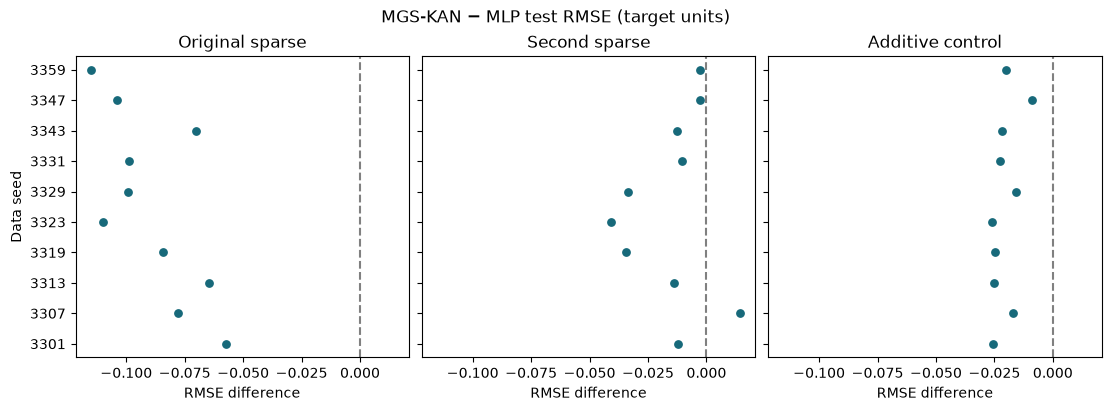

In [16]:
follow_labels = {"sparse": "Original sparse", "sparse_overlap": "Second sparse", "additive": "Additive control"}
prediction = {}
for task in c.FOLLOWUP_TASKS:
    rows = [r for r in follow_paired if r["task"] == task]
    delta = np.array([r["difference"] for r in rows])
    prediction[task] = {
        "kan": np.mean([r["mgs_kan"] for r in rows]), "mlp": np.mean([r["mlp"] for r in rows]),
        "mean": delta.mean(), "best": delta.min(), "worst": delta.max(), "wins": (delta < 0).sum(),
    }
table(["Task", "MGS-KAN mean", "MLP mean", "Mean difference", "Difference range", "MGS-KAN wins"],
      [(follow_labels[task], f"{r['kan']:.4f}", f"{r['mlp']:.4f}", f"{r['mean']:+.4f}",
        f"{r['best']:+.4f} to {r['worst']:+.4f}", f"{r['wins']}/10") for task, r in prediction.items()])

table(["Task", "Data seed", "MGS-KAN mean", "MLP mean", "MGS-KAN − MLP"],
      [(follow_labels[r["task"]], r["data_seed"], f"{r['mgs_kan']:.4f}",
        f"{r['mlp']:.4f}", f"{r['difference']:+.4f}") for r in follow_paired])

fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharex=True, sharey=True, layout="constrained")
for ax, task in zip(axes, c.FOLLOWUP_TASKS):
    rows = [r for r in follow_paired if r["task"] == task]
    ax.axvline(0, color="0.5", linestyle="--")
    ax.scatter([r["difference"] for r in rows], [str(r["data_seed"]) for r in rows], color="#17697a", s=28)
    ax.set(title=follow_labels[task], xlabel="RMSE difference")
axes[0].set_ylabel("Data seed")
fig.suptitle("MGS-KAN − MLP test RMSE (target units)")
plt.show()

## Follow-up interaction recovery

A top-three hit uses rank only. An exact threshold recovery means every planted pair and zero unplanted pairs crossed the frozen cutoff. For the additive control every threshold crossing is a false selection. Counts across initializations describe fits on shared splits. The accompanying split counts show how often all three initializations agreed on exact recovery.

| Task | All planted in top three | Exact cutoff fits | Exact across all 3 inits | Missed planted pairs | False selections | Fits with false selections |
| --- | --- | --- | --- | --- | --- | --- |
| Original sparse | 30/30 | 30/30 | 10/10 seeds | 0 | 0 | 0/30 |
| Second sparse | 30/30 | 30/30 | 10/10 seeds | 0 | 0 | 0/30 |
| Additive control | — | 30/30 | 10/10 seeds | 0 | 0 | 0/30 |

| Task | Pair | Best rank | Median rank | Worst rank |
| --- | --- | --- | --- | --- |
| Original sparse | (0, 1) | 1 | 1 | 2 |
| Original sparse | (2, 3) | 1 | 2 | 2 |
| Original sparse | (4, 5) | 3 | 3 | 3 |
| Second sparse | (0, 2) | 1 | 1 | 2 |
| Second sparse | (1, 5) | 1 | 2 | 3 |
| Second sparse | (2, 4) | 2 | 3 | 3 |

**Original sparse**

| Data seed | Init | Rank (0, 1) | Rank (2, 3) | Rank (4, 5) | Selected planted | False selections | Cutoff |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 3301 | 71 | 1 | 2 | 3 | 3 | 0 | 0.04962 |
| 3301 | 73 | 1 | 2 | 3 | 3 | 0 | 0.04962 |
| 3301 | 79 | 1 | 2 | 3 | 3 | 0 | 0.04962 |
| 3307 | 71 | 1 | 2 | 3 | 3 | 0 | 0.04944 |
| 3307 | 73 | 1 | 2 | 3 | 3 | 0 | 0.04944 |
| 3307 | 79 | 1 | 2 | 3 | 3 | 0 | 0.04944 |
| 3313 | 71 | 1 | 2 | 3 | 3 | 0 | 0.04994 |
| 3313 | 73 | 1 | 2 | 3 | 3 | 0 | 0.04994 |
| 3313 | 79 | 1 | 2 | 3 | 3 | 0 | 0.04994 |
| 3319 | 71 | 1 | 2 | 3 | 3 | 0 | 0.05008 |
| 3319 | 73 | 1 | 2 | 3 | 3 | 0 | 0.05008 |
| 3319 | 79 | 1 | 2 | 3 | 3 | 0 | 0.05008 |
| 3323 | 71 | 1 | 2 | 3 | 3 | 0 | 0.05150 |
| 3323 | 73 | 1 | 2 | 3 | 3 | 0 | 0.05150 |
| 3323 | 79 | 1 | 2 | 3 | 3 | 0 | 0.05150 |
| 3329 | 71 | 2 | 1 | 3 | 3 | 0 | 0.05118 |
| 3329 | 73 | 2 | 1 | 3 | 3 | 0 | 0.05118 |
| 3329 | 79 | 2 | 1 | 3 | 3 | 0 | 0.05118 |
| 3331 | 71 | 1 | 2 | 3 | 3 | 0 | 0.04986 |
| 3331 | 73 | 1 | 2 | 3 | 3 | 0 | 0.04986 |
| 3331 | 79 | 2 | 1 | 3 | 3 | 0 | 0.04986 |
| 3343 | 71 | 1 | 2 | 3 | 3 | 0 | 0.05124 |
| 3343 | 73 | 1 | 2 | 3 | 3 | 0 | 0.05124 |
| 3343 | 79 | 1 | 2 | 3 | 3 | 0 | 0.05124 |
| 3347 | 71 | 1 | 2 | 3 | 3 | 0 | 0.04908 |
| 3347 | 73 | 1 | 2 | 3 | 3 | 0 | 0.04908 |
| 3347 | 79 | 1 | 2 | 3 | 3 | 0 | 0.04908 |
| 3359 | 71 | 1 | 2 | 3 | 3 | 0 | 0.05170 |
| 3359 | 73 | 1 | 2 | 3 | 3 | 0 | 0.05170 |
| 3359 | 79 | 1 | 2 | 3 | 3 | 0 | 0.05170 |

**Second sparse**

| Data seed | Init | Rank (0, 2) | Rank (1, 5) | Rank (2, 4) | Selected planted | False selections | Cutoff |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 3301 | 71 | 1 | 2 | 3 | 3 | 0 | 0.04923 |
| 3301 | 73 | 1 | 2 | 3 | 3 | 0 | 0.04923 |
| 3301 | 79 | 1 | 2 | 3 | 3 | 0 | 0.04923 |
| 3307 | 71 | 1 | 2 | 3 | 3 | 0 | 0.04941 |
| 3307 | 73 | 1 | 2 | 3 | 3 | 0 | 0.04941 |
| 3307 | 79 | 1 | 2 | 3 | 3 | 0 | 0.04941 |
| 3313 | 71 | 1 | 2 | 3 | 3 | 0 | 0.04945 |
| 3313 | 73 | 1 | 2 | 3 | 3 | 0 | 0.04945 |
| 3313 | 79 | 1 | 2 | 3 | 3 | 0 | 0.04945 |
| 3319 | 71 | 1 | 2 | 3 | 3 | 0 | 0.05080 |
| 3319 | 73 | 1 | 2 | 3 | 3 | 0 | 0.05080 |
| 3319 | 79 | 1 | 2 | 3 | 3 | 0 | 0.05080 |
| 3323 | 71 | 2 | 1 | 3 | 3 | 0 | 0.05058 |
| 3323 | 73 | 1 | 2 | 3 | 3 | 0 | 0.05058 |
| 3323 | 79 | 1 | 2 | 3 | 3 | 0 | 0.05058 |
| 3329 | 71 | 1 | 2 | 3 | 3 | 0 | 0.05059 |
| 3329 | 73 | 1 | 2 | 3 | 3 | 0 | 0.05059 |
| 3329 | 79 | 1 | 2 | 3 | 3 | 0 | 0.05059 |
| 3331 | 71 | 1 | 2 | 3 | 3 | 0 | 0.05109 |
| 3331 | 73 | 1 | 2 | 3 | 3 | 0 | 0.05109 |
| 3331 | 79 | 1 | 2 | 3 | 3 | 0 | 0.05109 |
| 3343 | 71 | 1 | 2 | 3 | 3 | 0 | 0.05137 |
| 3343 | 73 | 1 | 2 | 3 | 3 | 0 | 0.05137 |
| 3343 | 79 | 1 | 2 | 3 | 3 | 0 | 0.05137 |
| 3347 | 71 | 2 | 1 | 3 | 3 | 0 | 0.04970 |
| 3347 | 73 | 1 | 2 | 3 | 3 | 0 | 0.04970 |
| 3347 | 79 | 1 | 2 | 3 | 3 | 0 | 0.04970 |
| 3359 | 71 | 1 | 2 | 3 | 3 | 0 | 0.04969 |
| 3359 | 73 | 1 | 3 | 2 | 3 | 0 | 0.04969 |
| 3359 | 79 | 1 | 2 | 3 | 3 | 0 | 0.04969 |

**Additive control**

| Data seed | Init | Selected planted | False selections | Cutoff |
| --- | --- | --- | --- | --- |
| 3301 | 71 | 0 | 0 | 0.04946 |
| 3301 | 73 | 0 | 0 | 0.04946 |
| 3301 | 79 | 0 | 0 | 0.04946 |
| 3307 | 71 | 0 | 0 | 0.04845 |
| 3307 | 73 | 0 | 0 | 0.04845 |
| 3307 | 79 | 0 | 0 | 0.04845 |
| 3313 | 71 | 0 | 0 | 0.05032 |
| 3313 | 73 | 0 | 0 | 0.05032 |
| 3313 | 79 | 0 | 0 | 0.05032 |
| 3319 | 71 | 0 | 0 | 0.04941 |
| 3319 | 73 | 0 | 0 | 0.04941 |
| 3319 | 79 | 0 | 0 | 0.04941 |
| 3323 | 71 | 0 | 0 | 0.05139 |
| 3323 | 73 | 0 | 0 | 0.05139 |
| 3323 | 79 | 0 | 0 | 0.05139 |
| 3329 | 71 | 0 | 0 | 0.05032 |
| 3329 | 73 | 0 | 0 | 0.05032 |
| 3329 | 79 | 0 | 0 | 0.05032 |
| 3331 | 71 | 0 | 0 | 0.05013 |
| 3331 | 73 | 0 | 0 | 0.05013 |
| 3331 | 79 | 0 | 0 | 0.05013 |
| 3343 | 71 | 0 | 0 | 0.05214 |
| 3343 | 73 | 0 | 0 | 0.05214 |
| 3343 | 79 | 0 | 0 | 0.05214 |
| 3347 | 71 | 0 | 0 | 0.04913 |
| 3347 | 73 | 0 | 0 | 0.04913 |
| 3347 | 79 | 0 | 0 | 0.04913 |
| 3359 | 71 | 0 | 0 | 0.05027 |
| 3359 | 73 | 0 | 0 | 0.05027 |
| 3359 | 79 | 0 | 0 | 0.05027 |

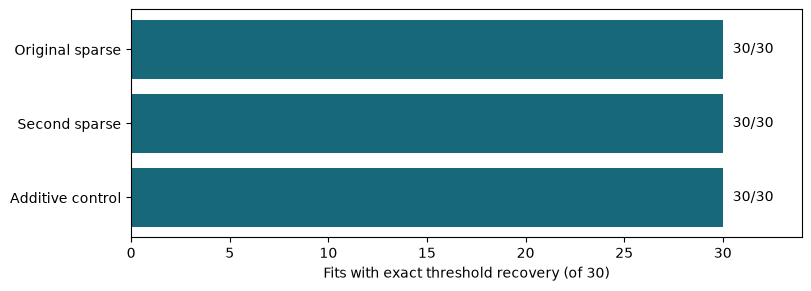

In [17]:
recovery_groups = {
    task: [r for r in follow_recovery if r["task"] == task] for task in c.FOLLOWUP_TASKS
}
recovery_results = {}
for task, rows in recovery_groups.items():
    planted = tuple(rows[0]["ranks"])
    exact = [r["selected_planted"] == len(planted) and r["false_selections"] == 0 for r in rows]
    recovery_results[task] = {
        "all_top_three": sum(r["top_three_hits"] == len(planted) for r in rows) if planted else None,
        "exact": sum(exact),
        "exact_seeds": sum(all(ok for ok, r in zip(exact, rows) if r["data_seed"] == seed)
                           for seed in c.FOLLOWUP_DATA_SEEDS),
        "misses": sum(len(planted) - r["selected_planted"] for r in rows),
        "false": sum(r["false_selections"] for r in rows),
        "false_fits": sum(r["false_selections"] > 0 for r in rows),
    }

table(["Task", "All planted in top three", "Exact cutoff fits", "Exact across all 3 inits",
       "Missed planted pairs", "False selections", "Fits with false selections"],
      [(follow_labels[task], f"{r['all_top_three']}/30" if r["all_top_three"] is not None else "—",
        f"{r['exact']}/30", f"{r['exact_seeds']}/10 seeds", r["misses"], r["false"],
        f"{r['false_fits']}/30") for task, r in recovery_results.items()])

table(["Task", "Pair", "Best rank", "Median rank", "Worst rank"],
      [(follow_labels[task], pair, min(ranks), f"{np.median(ranks):g}", max(ranks))
       for task, rows in recovery_groups.items() for pair in rows[0]["ranks"]
       for ranks in [[r["ranks"][pair] for r in rows]]])

for task, rows in recovery_groups.items():
    display(Markdown(f"**{follow_labels[task]}**"))
    planted = tuple(rows[0]["ranks"])
    table(["Data seed", "Init", *(f"Rank {p}" for p in planted), "Selected planted", "False selections", "Cutoff"],
          [(r["data_seed"], r["init_seed"], *(r["ranks"][p] for p in planted),
            r["selected_planted"], r["false_selections"], f"{r['threshold']:.5f}") for r in rows])

fig, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
names = list(follow_labels.values())
hits = [recovery_results[task]["exact"] for task in c.FOLLOWUP_TASKS]
ax.barh(names, hits, color="#17697a")
for i, hit in enumerate(hits):
    ax.text(hit + 0.5, i, f"{hit}/30", va="center")
ax.set(xlim=(0, 34), xlabel="Fits with exact threshold recovery (of 30)")
ax.invert_yaxis()
plt.show()

## Follow-up run cost

The saved per-fit durations measure training and validation. Fit durations may overlap in wall time when workers run concurrently.

In [18]:
runtime = follow_protocol["settings"]["runtime"]
print(f"{runtime['device']} • {runtime['cpu']} • {c.FOLLOWUP_WORKERS} workers, {c.THREADS} thread each")
print(f"This follow-up execution through verification {follow_elapsed / 60:.2f} min.")
table(["Model", "Trainable parameters", "Final fits", "Median seconds", "Sum of recorded seconds"],
      [(model, follow_checks["parameter_counts"][model], len(times), f"{np.median(times):.2f}", f"{sum(times):.2f}")
       for model in c.MODELS for times in [[r["training_seconds"] for r in follow_fits if r["model"] == model]]])

cpu • Intel(R) Core(TM) i5-9400F CPU @ 2.90GHz • 5 workers, 1 thread each
This follow-up execution through verification 5.35 min.


| Model | Trainable parameters | Final fits | Median seconds | Sum of recorded seconds |
| --- | --- | --- | --- | --- |
| mgs_kan | 949 | 90 | 9.68 | 899.05 |
| mlp | 937 | 90 | 3.90 | 357.42 |

## Follow-up verdict

In [19]:
sparse_tasks = ("sparse", "sparse_overlap")
accuracy_lines, recovery_lines = [], []
for task in sparse_tasks:
    label, p, r = follow_labels[task], prediction[task], recovery_results[task]
    accuracy_lines.append(
        f"{label} mean RMSE was {p['kan']:.4f} for MGS-KAN and {p['mlp']:.4f} for the MLP, "
        f"with {p['wins']}/10 MGS-KAN wins and differences from {p['best']:+.4f} to "
        f"{p['worst']:+.4f} target units."
    )
    recovery_lines.append(
        f"{label} placed all three planted pairs in the top three in {r['all_top_three']}/30 fits. "
        f"Exact cutoff recovery occurred in {r['exact']}/30 fits, with {r['misses']} missed "
        f"planted pairs and {r['false']} false selections in total."
    )

ctrl = recovery_results["additive"]
display(Markdown(f"""
**Prediction.** {' '.join(accuracy_lines)}

**Interaction recovery.** {' '.join(recovery_lines)} The additive control produced
{ctrl['false']} false selections across {ctrl['false_fits']}/30 fits.

**Scope.** The two sparse targets test different interaction shapes under the same input distribution.
The independent units for prediction are 10 data seeds per target. Recovery counts describe
the learned MGS-KAN pair terms under the fixed practical cutoff.
""".replace("\n    ", "\n").strip()))

**Prediction.** Original sparse mean RMSE was 0.2403 for MGS-KAN and 0.3284 for the MLP, with 10/10 MGS-KAN wins and differences from -0.1152 to -0.0572 target units. Second sparse mean RMSE was 0.2858 for MGS-KAN and 0.3007 for the MLP, with 9/10 MGS-KAN wins and differences from -0.0410 to +0.0144 target units.

**Interaction recovery.** Original sparse placed all three planted pairs in the top three in 30/30 fits. Exact cutoff recovery occurred in 30/30 fits, with 0 missed planted pairs and 0 false selections in total. Second sparse placed all three planted pairs in the top three in 30/30 fits. Exact cutoff recovery occurred in 30/30 fits, with 0 missed planted pairs and 0 false selections in total. The additive control produced
0 false selections across 0/30 fits.

**Scope.** The two sparse targets test different interaction shapes under the same input distribution.
The independent units for prediction are 10 data seeds per target. Recovery counts describe
the learned MGS-KAN pair terms under the fixed practical cutoff.

# Why did the prediction gain shrink?

This post-hoc analysis uses the 120 saved follow-up checkpoints on the two sparse targets. It estimates shape error for the three planted interactions in each target, then examines seed 3307 separately. The original prediction and recovery results above use their frozen protocol.

For a predictor $f$, let $h_{ij}(u,v)=E[f(X)mid X_i=u,X_j=v]$ under the generator's independent standard-normal inputs. Its pure pair surface is $h_{ij}$ minus its two marginal means plus its grand mean. Apply the same operation to the noiseless generator and integrate the squared surface difference. This measures **interaction-shape error in squared target units** for both models. First-order projections capture single-coordinate errors, including main effects contributed by the planted Gaussian and ridge.

Use 40 Gauss–Hermite nodes per coordinate with standard-normal weights. For the MLP, estimate conditional means by averaging over 256 scrambled Sobol normal backgrounds shared across models, splits and grid points. The MGS-KAN projections come directly from its affine, univariate and pair terms. Estimate total signal MSE on a separate common draw of 32,768 Sobol normal inputs. Under the independent input distribution, distinct pure pairs and first-order terms are orthogonal, even when two pairs share a coordinate. The difference between total MSE and the reported components includes unplanted and higher-order errors and numerical integration error.

In [20]:
from hashlib import sha256
from itertools import product
import torch

from src.data import _components, _overlap_components, make_data, planted_pairs
from src.models import make_model


def calibration(raw, task, reference):
    components = _components(raw)
    stats = reference
    if task == "sparse_overlap":
        components = _overlap_components(raw, components[:, :3])
        stats = reference["overlap"]
    target = reference["targets"][task]
    components = (components - stats["component_mean"]) / stats["component_sd"]
    return (components.sum(axis=1) - target["mean"]) / target["sd"], components / target["sd"]


def normal_sobol(dim, seed, power):
    uniform = torch.quasirandom.SobolEngine(dim, scramble=True, seed=seed).draw_base2(power, dtype=torch.float64)
    return torch.special.ndtri(uniform.clamp(1e-12, 1 - 1e-12))


def center(surface, weights):
    return surface - (surface @ weights)[:, None] - (weights @ surface)[None, :] + weights @ surface @ weights


def axes_normal(nodes):
    axes, weights = np.polynomial.hermite.hermgauss(nodes)
    return torch.from_numpy(axes * np.sqrt(2)), torch.from_numpy(weights / np.sqrt(np.pi))


def pair_input(axis, pair):
    grid = axis.new_zeros((axis.numel() ** 2, c.FEATURES))
    grid[:, pair] = torch.cartesian_prod(axis, axis)
    return grid


def conditional_mean(model, values, coordinates, background, mean, scale):
    means = []
    for block in values.split(48):
        points = background.expand(len(block), -1, -1).clone()
        points[:, :, list(coordinates)] = block[:, None, :]
        scaled = ((points - mean) / scale).float().flatten(0, 1)
        means.append(model(scaled).reshape(len(block), -1).double().mean(dim=1))
    return torch.cat(means)


def main_effects(values, weights):
    return values - weights @ values


def projections(model, name, pairs, axis, weights, background, mean, scale):
    rows = len(axis)
    grid = torch.cartesian_prod(axis, axis)
    if name == "mgs_kan":
        scaled = (axis[:, None] - mean) / scale
        i, j = model.pairs.T
        surfaces = model.pair_values(scaled[:, None, i], scaled[None, :, j])
        main = scaled * model.affine.weight[0] + model.contributions(scaled)[1]
        main.index_add_(1, i, torch.einsum("uvp,v->up", surfaces, weights))
        main.index_add_(1, j, torch.einsum("uvp,u->vp", surfaces, weights))
        indices = [model.pairs.tolist().index(list(pair)) for pair in pairs]
        pair_surfaces = [surfaces[:, :, index] for index in indices]
    else:
        main = torch.stack([
            conditional_mean(model, axis[:, None], (i,), background, mean, scale)
            for i in range(c.FEATURES)
        ], dim=1)
        pair_surfaces = [
            conditional_mean(model, grid, pair, background, mean, scale).reshape(rows, rows)
            for pair in pairs
        ]
    return main_effects(main, weights), [center(surface, weights) for surface in pair_surfaces]


def truth_projections(task, reference, axis, weights):
    anchors = axis[:, None].expand(-1, c.FEATURES)
    additive = torch.from_numpy(calibration(anchors.numpy(), task, reference)[1][:, :3])
    main = axis.new_zeros((len(axis), c.FEATURES))
    main[:, list(c.ADDITIVE_FEATURES)] = additive
    pure = {}
    for idx, pair in enumerate(planted_pairs(task), start=3):
        raw = pair_input(axis, pair)
        surface = torch.from_numpy(calibration(raw.numpy(), task, reference)[1][:, idx])
        surface = surface.reshape(len(axis), len(axis))
        i, j = pair
        main[:, i] += surface @ weights
        main[:, j] += weights @ surface
        pure[pair] = center(surface, weights)
    return main_effects(main, weights), pure


@torch.inference_mode()
def interaction_analysis(output, protocol, nodes=40, power=8, context_seed=5317,
                         seeds=c.FOLLOWUP_DATA_SEEDS, tasks=("sparse", "sparse_overlap")):
    manifest = json.loads((output / "final" / "manifest.json").read_text())
    assert manifest["protocol_id"] == protocol["id"]
    reference = protocol["reference"]
    axis, weights = axes_normal(nodes)
    background = normal_sobol(c.FEATURES, context_seed, power)
    population = normal_sobol(c.FEATURES, 6899, 15)
    truth = {task: truth_projections(task, reference, axis, weights) for task in tasks}
    population_truth = {task: torch.from_numpy(calibration(population.numpy(), task, reference)[0]) for task in tasks}
    pair_rows, fit_rows, focus = [], [], []
    for task, seed in product(tasks, seeds):
        feature_seed, noise_seed = np.random.SeedSequence(seed).spawn(2)
        raw = np.random.default_rng(feature_seed).standard_normal((sum(c.SPLIT_SIZES), c.FEATURES))
        training_raw = raw[:c.SPLIT_SIZES[0]]
        mean, scale = map(torch.from_numpy, (training_raw.mean(axis=0), training_raw.std(axis=0)))
        held_out_rows = torch.arange(sum(c.SPLIT_SIZES[:2]), sum(c.SPLIT_SIZES))
        splits, _ = make_data(task, seed, reference)
        assert torch.equal(((torch.from_numpy(raw[held_out_rows]) - mean) / scale).float(), splits[2][0])
        clean = torch.from_numpy(calibration(raw[held_out_rows], task, reference)[0])
        noise = np.random.default_rng(noise_seed).normal(0., c.NOISE_SD, len(raw))
        assert torch.equal((clean + torch.from_numpy(noise[held_out_rows])).float(), splits[2][1])
        population_x = ((population - mean) / scale).float()
        for init, name in product(c.INIT_SEEDS, c.MODELS):
            key = f"{task}-{seed}-{init}-{name}"
            meta = manifest["fits"][key]
            path = output / meta["artifact"]
            assert sha256(path.read_bytes()).hexdigest() == meta["sha256"]
            bundle = torch.load(path, weights_only=True, map_location="cpu")
            assert torch.equal(bundle["test"]["rows"], held_out_rows)
            assert torch.equal(bundle["test"]["target"], splits[2][1])
            model = make_model(name).eval()
            model.load_state_dict(bundle["checkpoint"])
            pred = bundle["test"]["prediction"].double()
            test_y = bundle["test"]["target"].double()
            pop_pred = torch.cat([model(batch) for batch in population_x.split(1024)]).double()
            fit = {"task": task, "seed": seed, "init": init, "model": name,
                   "epoch": meta["best_epoch"], "epochs_run": meta["epochs_run"],
                   "noisy_val_rmse": meta["validation_rmse"],
                   "noisy_test_rmse": meta["test_rmse"],
                   "noisy_test_mse": (pred - test_y).square().mean().item(),
                   "clean_test_mse": (pred - clean).square().mean().item(),
                   "population_mse": (pop_pred - population_truth[task]).square().mean().item()}
            if name == "mgs_kan":
                model.double()
            pairs = planted_pairs(task)
            model_main, surfaces = projections(model, name, pairs, axis, weights, background, mean, scale)
            truth_main, truth_surfaces = truth[task]
            fit["first_order_mse"] = (weights @ (model_main - truth_main).square()).sum().item()
            fit["squared_bias"] = (pop_pred - population_truth[task]).mean().square().item()
            fit_rows.append(fit)
            for pair, surface in zip(pairs, surfaces):
                target = truth_surfaces[pair]
                error = weights @ (surface - target).square() @ weights
                pair_rows.append({**{k: fit[k] for k in ("task", "seed", "init", "model")},
                                  "pair": pair, "mse": error.item()})
                if task == "sparse_overlap" and seed == 3307:
                    focus.append((pair, name, surface.numpy()))
    return fit_rows, pair_rows, axis.numpy(), truth, focus


def average(rows, key):
    return float(np.mean([row[key] for row in rows]))

In [21]:
axis_check, weight_check = axes_normal(40)
additive_check = axis_check[:, None].square() + axis_check[None, :].sin()
product_check = axis_check[:, None] * axis_check[None, :]
assert center(additive_check, weight_check).abs().max() < 1e-12
torch.testing.assert_close(center(product_check, weight_check), product_check, atol=1e-12, rtol=0)
torch.testing.assert_close(weight_check @ product_check.square() @ weight_check, torch.tensor(1., dtype=torch.float64))

diagnostic_fits, diagnostic_pairs, diagnostic_axis, diagnostic_truth, focus_surfaces = interaction_analysis(
    follow_output, follow_protocol,
)
assert len(diagnostic_fits) == 120 and len(diagnostic_pairs) == 360
print("Checked conditional centering, regenerated holdout targets and loaded 120 verified checkpoints.")

Checked conditional centering, regenerated holdout targets and loaded 120 verified checkpoints.


## Error by planted interaction

MSE averages are across fits. For each cohort, the models contribute the same number of fits for every data seed. A positive difference means the MLP approximates that interaction more accurately.

In [22]:
pair_names = {
    "sparse": ("Product", "Sine of product", "Rotated Gaussian"),
    "sparse_overlap": ("Tanh product", "Gaussian ridge", "Oscillatory product"),
}
cohorts = (
    ("Original sparse • all seeds", "sparse", c.FOLLOWUP_DATA_SEEDS),
    ("Second sparse • all seeds", "sparse_overlap", c.FOLLOWUP_DATA_SEEDS),
    ("Second sparse • other nine seeds", "sparse_overlap", tuple(s for s in c.FOLLOWUP_DATA_SEEDS if s != 3307)),
    ("Second sparse • seed 3307", "sparse_overlap", (3307,)),
)

def diagnostic_summary(task, seeds, fit_rows=diagnostic_fits, pair_rows=diagnostic_pairs):
    results = {}
    for name in c.MODELS:
        fits = [r for r in fit_rows if (r["task"], r["model"]) == (task, name) and r["seed"] in seeds]
        assert len(fits) == len(seeds) * len(c.INIT_SEEDS)
        pair_mse = {
            pair: average([r for r in pair_rows if (r["task"], r["model"], r["pair"]) == (task, name, pair)
                           and r["seed"] in seeds], "mse")
            for pair in planted_pairs(task)
        }
        summary = {measure: average(fits, measure) for measure in (
            "noisy_test_mse", "clean_test_mse", "population_mse", "first_order_mse", "squared_bias",
        )}
        summary["planted_mse"] = sum(pair_mse.values())
        summary["remainder"] = (summary["population_mse"] - summary["planted_mse"]
                                - summary["first_order_mse"] - summary["squared_bias"])
        results[name] = {**summary, "pair_mse": pair_mse}
    return results

diagnostic_groups = {label: diagnostic_summary(task, seeds) for label, task, seeds in cohorts}
pair_table_rows = []
for label, task, seeds in cohorts:
    kan, mlp = (diagnostic_groups[label][name]["pair_mse"] for name in c.MODELS)
    for pair, shape in zip(planted_pairs(task), pair_names[task]):
        pair_table_rows.append((label, pair, shape, f"{kan[pair]:.5f}", f"{mlp[pair]:.5f}",
                                f"{kan[pair] - mlp[pair]:+.5f}"))
table(["Cohort", "Pair", "True component", "MGS-KAN MSE", "MLP MSE", "MGS-KAN − MLP"],
      pair_table_rows)

| Cohort | Pair | True component | MGS-KAN MSE | MLP MSE | MGS-KAN − MLP |
| --- | --- | --- | --- | --- | --- |
| Original sparse • all seeds | (0, 1) | Product | 0.00988 | 0.00317 | +0.00671 |
| Original sparse • all seeds | (2, 3) | Sine of product | 0.02632 | 0.04095 | -0.01463 |
| Original sparse • all seeds | (4, 5) | Rotated Gaussian | 0.00074 | 0.00249 | -0.00175 |
| Second sparse • all seeds | (0, 2) | Tanh product | 0.00478 | 0.00309 | +0.00170 |
| Second sparse • all seeds | (1, 5) | Gaussian ridge | 0.00045 | 0.00143 | -0.00098 |
| Second sparse • all seeds | (2, 4) | Oscillatory product | 0.05349 | 0.02712 | +0.02636 |
| Second sparse • other nine seeds | (0, 2) | Tanh product | 0.00493 | 0.00314 | +0.00179 |
| Second sparse • other nine seeds | (1, 5) | Gaussian ridge | 0.00047 | 0.00148 | -0.00101 |
| Second sparse • other nine seeds | (2, 4) | Oscillatory product | 0.05325 | 0.02739 | +0.02585 |
| Second sparse • seed 3307 | (0, 2) | Tanh product | 0.00349 | 0.00262 | +0.00087 |
| Second sparse • seed 3307 | (1, 5) | Gaussian ridge | 0.00029 | 0.00098 | -0.00070 |
| Second sparse • seed 3307 | (2, 4) | Oscillatory product | 0.05565 | 0.02468 | +0.03098 |

## Which errors changed the overall gap?

The table separates estimated total signal MSE into the sum of the three planted pair errors, the sum of first-order errors, squared mean prediction bias, and the remaining error. Every column shows MGS-KAN minus MLP in squared target units.

In [23]:
budget_keys = ("population_mse", "planted_mse", "first_order_mse", "squared_bias", "remainder")
gaps = {
    label: {metric: group["mgs_kan"][metric] - group["mlp"][metric] for metric in budget_keys}
    for label, group in diagnostic_groups.items()
}
table(["Cohort", "Total signal MSE", "Planted pairs", "First-order effects", "Squared bias", "Remainder"],
      [(label, *(f"{gap[metric]:+.5f}" for metric in budget_keys)) for label, gap in gaps.items()])

| Cohort | Total signal MSE | Planted pairs | First-order effects | Squared bias | Remainder |
| --- | --- | --- | --- | --- | --- |
| Original sparse • all seeds | -0.04972 | -0.00967 | -0.00671 | -0.00017 | -0.03318 |
| Second sparse • all seeds | -0.00832 | +0.02708 | -0.00215 | +0.00003 | -0.03328 |
| Second sparse • other nine seeds | -0.00990 | +0.02663 | -0.00248 | +0.00004 | -0.03409 |
| Second sparse • seed 3307 | +0.00587 | +0.03115 | +0.00079 | -0.00005 | -0.02602 |

## Seed 3307

The saved validation and test RMSE columns use the noisy labels from the original comparison. The clean holdout MSE uses the same rows with the noiseless target. The independent-input column uses the separate normal draw and the noiseless target. The last three columns show paired differences in MSE. Positive values favor the MLP.

In [24]:
focus_fits = [r for r in diagnostic_fits if (r["task"], r["seed"]) == ("sparse_overlap", 3307)]
focus_by_init = {
    init: [next(r for r in focus_fits if (r["init"], r["model"]) == (init, name)) for name in c.MODELS]
    for init in c.INIT_SEEDS
}
table(["Init", "MGS-KAN val RMSE", "MLP val RMSE", "MGS-KAN test RMSE", "MLP test RMSE",
       "Δ noisy holdout MSE", "Δ clean holdout MSE", "Δ independent signal MSE"],
      [(init, f"{kan['noisy_val_rmse']:.4f}", f"{mlp['noisy_val_rmse']:.4f}",
        f"{kan['noisy_test_rmse']:.4f}", f"{mlp['noisy_test_rmse']:.4f}",
        *(f"{kan[key] - mlp[key]:+.5f}" for key in ("noisy_test_mse", "clean_test_mse", "population_mse")))
       for init, (kan, mlp) in focus_by_init.items()])

| Init | MGS-KAN val RMSE | MLP val RMSE | MGS-KAN test RMSE | MLP test RMSE | Δ noisy holdout MSE | Δ clean holdout MSE | Δ independent signal MSE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 71 | 0.2751 | 0.2725 | 0.2884 | 0.2772 | +0.00634 | +0.00524 | +0.00620 |
| 73 | 0.2826 | 0.2517 | 0.2895 | 0.2586 | +0.01694 | +0.01662 | +0.01400 |
| 79 | 0.2777 | 0.2691 | 0.2871 | 0.2860 | +0.00062 | -0.00082 | -0.00258 |

The maps show the true and fitted pure surfaces for the oscillatory pair on seed 3307. The fitted surfaces are averaged across the three initializations for display. The error tables average squared errors from individual fits.

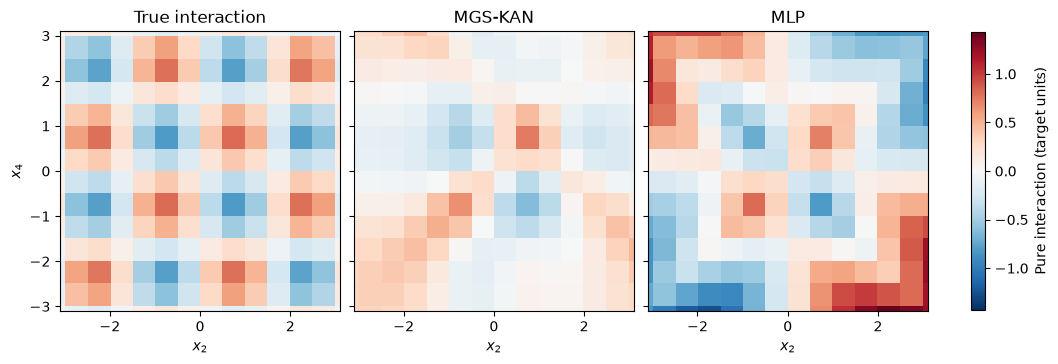

In [25]:
osc_pair = (2, 4)
true_osc = diagnostic_truth["sparse_overlap"][1][osc_pair].numpy()
surfaces = [true_osc] + [
    np.mean([surface for pair, model, surface in focus_surfaces if (pair, model) == (osc_pair, name)], axis=0)
    for name in c.MODELS
]
view = np.ix_(np.abs(diagnostic_axis) <= 3.4, np.abs(diagnostic_axis) <= 3.4)
limit = max(np.abs(surface[view]).max() for surface in surfaces)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6), sharex=True, sharey=True, layout="constrained")
for ax, title, surface in zip(axes, ("True interaction", "MGS-KAN", "MLP"), surfaces):
    mesh = ax.pcolormesh(diagnostic_axis, diagnostic_axis, surface.T, cmap="RdBu_r",
                         vmin=-limit, vmax=limit, shading="nearest")
    ax.set(title=title, xlabel="$x_2$", xlim=(-3.1, 3.1), ylim=(-3.1, 3.1), aspect="equal")
axes[0].set_ylabel("$x_4$")
fig.colorbar(mesh, ax=axes, label="Pure interaction (target units)", shrink=0.83)
plt.show()

### Numerical sensitivity and interpretation

Repeat the seed 3307 projection with 64 nodes and 512 backgrounds using a different Sobol scramble. This checks the estimated pair-error difference against a denser grid and a larger conditional sample.

In [26]:
fine_fits, fine_pairs, *_ = interaction_analysis(
    follow_output, follow_protocol, nodes=64, power=9, context_seed=5413, seeds=(3307,), tasks=("sparse_overlap",),
)
focus_label = "Second sparse • seed 3307"
coarse = diagnostic_groups[focus_label]
fine = diagnostic_summary("sparse_overlap", (3307,), fine_fits, fine_pairs)
table(["Projection grid and backgrounds", "MGS-KAN MSE (2,4)", "MLP MSE (2,4)", "MGS-KAN − MLP"],
      [(setting, f"{kan:.5f}", f"{mlp:.5f}", f"{kan - mlp:+.5f}")
       for setting, result in (("40 nodes, 256 backgrounds", coarse), ("64 nodes, 512 backgrounds", fine))
       for kan, mlp in [[result[name]["pair_mse"][osc_pair] for name in c.MODELS]]])

original_gap, second_gap, other_gap, focus_gap = gaps.values()
total_shift = second_gap["population_mse"] - original_gap["population_mse"]
pair_shift = second_gap["planted_mse"] - original_gap["planted_mse"]
osc_kan, osc_mlp = (coarse[name]["pair_mse"][osc_pair] for name in c.MODELS)
focus_noise_gap = coarse["mgs_kan"]["noisy_test_mse"] - coarse["mlp"]["noisy_test_mse"]
focus_clean_gap = coarse["mgs_kan"]["clean_test_mse"] - coarse["mlp"]["clean_test_mse"]
second = diagnostic_groups["Second sparse • all seeds"]
others = diagnostic_groups["Second sparse • other nine seeds"]
second_osc_kan, second_osc_mlp = (second[name]["pair_mse"][osc_pair] for name in c.MODELS)

display(Markdown(f"""
**Why the gain shrank.** From the original target to the second, the gap in total noiseless
MSE moved by {total_shift:+.5f} toward the MLP. The change in the three planted pair errors
was {pair_shift:+.5f}, or {pair_shift / total_shift:.0%} of that shift. MGS-KAN had a
lower error on the original sine-of-product term. The second target favored the MLP
on the oscillatory product, with mean pair MSE of
{second_osc_kan:.5f} for MGS-KAN and {second_osc_mlp:.5f} for the MLP.

**Why seed 3307 reversed.** Its oscillatory pair MSE was {osc_kan:.5f} for MGS-KAN and
{osc_mlp:.5f} for the MLP. The MGS-KAN advantage in the remaining error was smaller
on seed 3307 ({focus_gap['remainder']:+.5f}) than across the other nine
({other_gap['remainder']:+.5f}). Most of this change came from the MLP's lower
remainder on seed 3307 ({coarse['mlp']['remainder']:.5f} versus {others['mlp']['remainder']:.5f}
across the other nine). The noisy holdout MSE difference was {focus_noise_gap:+.5f},
the clean holdout difference was {focus_clean_gap:+.5f}, and the independent signal
difference was {focus_gap['population_mse']:+.5f}. Initialization 73 had the largest
MLP advantage. Initialization 79 favored MGS-KAN on the independent draw.

**What this establishes.** All three planted pairs crossed the frozen recovery cutoff in
every fit on this target. The oscillatory pair nevertheless carried substantial shape
error. These projections explain where the saved models' errors differ. The target,
basis, optimizer and regularization effects would require controlled fits to isolate.
"""))

| Projection grid and backgrounds | MGS-KAN MSE (2,4) | MLP MSE (2,4) | MGS-KAN − MLP |
| --- | --- | --- | --- |
| 40 nodes, 256 backgrounds | 0.05565 | 0.02468 | +0.03098 |
| 64 nodes, 512 backgrounds | 0.05560 | 0.02413 | +0.03146 |


**Why the gain shrank.** From the original target to the second, the gap in total noiseless
MSE moved by +0.04140 toward the MLP. The change in the three planted pair errors
was +0.03675, or 89% of that shift. MGS-KAN had a
lower error on the original sine-of-product term. The second target favored the MLP
on the oscillatory product, with mean pair MSE of
0.05349 for MGS-KAN and 0.02712 for the MLP.

**Why seed 3307 reversed.** Its oscillatory pair MSE was 0.05565 for MGS-KAN and
0.02468 for the MLP. The MGS-KAN advantage in the remaining error was smaller
on seed 3307 (-0.02602) than across the other nine
(-0.03409). Most of this change came from the MLP's lower
remainder on seed 3307 (0.03238 versus 0.04078
across the other nine). The noisy holdout MSE difference was +0.00796,
the clean holdout difference was +0.00702, and the independent signal
difference was +0.00587. Initialization 73 had the largest
MLP advantage. Initialization 79 favored MGS-KAN on the independent draw.

**What this establishes.** All three planted pairs crossed the frozen recovery cutoff in
every fit on this target. The oscillatory pair nevertheless carried substantial shape
error. These projections explain where the saved models' errors differ. The target,
basis, optimizer and regularization effects would require controlled fits to isolate.


# Controlled fits for pair (2,4)

The preceding analysis found a shape error on the second sparse target's oscillatory product, $\sin(2x_2)\sin(2x_4)$. This experiment crosses three factors within MGS-KAN:

| Factor | Original level | Alternate level |
| --- | ---: | ---: |
| Gaussian kernels on pair (2,4) | 2 | 8 |
| Adam learning rate | 0.001 | 0.003 |
| Pair amplitude group penalty $\lambda$ | 0.001 | 0 |

Use all eight combinations on seed 3307 and the two closest follow-up seeds, 3301 and 3313, with the original three initializations on each split. That gives 72 matched fits. Within a split and initialization, all fits see the same examples in the same minibatch order and share the original parameters at initialization. The six added kernels have zero initial amplitude and independently drawn centers and precisions. Thus both widths start with the same predictor. All other pairs retain two kernels, so only 36 trainable parameters are added (949 → 985). The extra amplitudes share the existing group norm for pair (2,4). The intervention uses the planted pair from the prior diagnostic and is specific to this pair.

Each fit runs for 300 epochs. Save the checkpoint the original validation and patience rule would have selected, and separately save epoch 300. The first endpoint measures effects under the deployed checkpoint rule. The second compares equal numbers of optimizer updates. Verify that each two-kernel baseline exactly reproduces the previously saved validation history up to stopping and its selected test predictions.

The primary metric is pure interaction MSE in squared target units, using the preceding 40-node standard-normal quadrature. Whole-model clean signal MSE uses the same independent 32,768-row input draw. Report noisy test RMSE separately. The validation selection cutoff still measures the magnitude of the learned pair. The original study and follow-up remain the matched predictor comparisons. The larger basis here is a targeted intervention.

In [27]:
from experiments.pair_ablation import BASELINE as ABLATION_BASELINE, ENDPOINTS as ABLATION_ENDPOINTS
from experiments.pair_ablation import run_ablation

ablation_output, ablation_rows, ablation_elapsed = run_ablation(
    output_root / "ablation", follow_output, follow_protocol,
)
print(f"{len(ablation_rows) // 2} verified fits in {ablation_output / 'manifest.json'}")
print(f"This execution of the ablation stage took {ablation_elapsed:.1f} seconds.")

9/72 fits verified (9 reused)


18/72 fits verified (18 reused)


27/72 fits verified (27 reused)


36/72 fits verified (36 reused)


45/72 fits verified (45 reused)


54/72 fits verified (54 reused)


63/72 fits verified (63 reused)


72/72 fits verified (72 reused)


72 verified fits in outputs/study/ablation/d7acbb7046e862ad/manifest.json
This execution of the ablation stage took 3.7 seconds.


## Matched effects of each factor

For each factor, compare alternate minus original with data seed, initialization and the other two factors held fixed. The mean spans all such contrasts within a cohort. The range and count show consistency over the matched comparisons. Negative error differences favor the alternate level. These are descriptive contrasts, with repeated settings and initializations on the same three data splits.

In [28]:
ablation_factors = (
    ("Kernels 2 → 8", "kernels", 2, 8),
    ("LR 0.001 → 0.003", "lr", 0.001, 0.003),
    ("Penalty 0.001 → 0", "lambda", 0.001, 0.),
)
factor_fields = ("kernels", "lr", "lambda")
endpoint_labels = {"selected": "Validation-selected", "epoch_300": "Epoch 300"}
ablation_metrics = ("pair_mse", "signal_mse", "test_rmse")
ablation_index_fields = ("endpoint", "seed", "init", *factor_fields)
ablation_index = {tuple(r[field] for field in ablation_index_fields): r for r in ablation_rows}
assert len(ablation_index) == len(ablation_rows) == 144

def matched_effects(rows, field, original, alternate):
    differences = []
    for row in rows:
        if row[field] == alternate:
            index = [original if key == field else row[key] for key in ablation_index_fields]
            control = ablation_index[tuple(index)]
            differences.append([row[key] - control[key] for key in ablation_metrics])
    return np.array(differences)

effect_table = []
effect_values = {}
for endpoint in ABLATION_ENDPOINTS:
    for cohort, seeds in (("All three seeds", {3301, 3307, 3313}), ("Seed 3307", {3307})):
        rows = [r for r in ablation_rows if r["endpoint"] == endpoint and r["seed"] in seeds]
        for name, field, original, alternate in ablation_factors:
            differences = matched_effects(rows, field, original, alternate)
            assert len(differences) == len(seeds) * len(c.INIT_SEEDS) * 4
            pair_delta, signal_delta, rmse_delta = differences.T
            effect_values[endpoint, cohort, field] = pair_delta.mean()
            effect_table.append((
                endpoint_labels[endpoint], cohort, name, f"{pair_delta.mean():+.5f}",
                f"{pair_delta.min():+.5f} to {pair_delta.max():+.5f}",
                f"{(pair_delta < 0).sum()}/{len(pair_delta)}",
                f"{signal_delta.mean():+.5f}", f"{rmse_delta.mean():+.5f}",
            ))

table(["Endpoint", "Cohort", "Change", "Δ pair MSE", "Δ pair MSE range", "Pair improved",
       "Δ signal MSE", "Δ test RMSE"], effect_table)

| Endpoint | Cohort | Change | Δ pair MSE | Δ pair MSE range | Pair improved | Δ signal MSE | Δ test RMSE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Validation-selected | All three seeds | Kernels 2 → 8 | -0.03728 | -0.05100 to -0.02043 | 36/36 | -0.04465 | -0.09205 |
| Validation-selected | All three seeds | LR 0.001 → 0.003 | -0.00355 | -0.02090 to +0.00052 | 28/36 | -0.00352 | -0.00795 |
| Validation-selected | All three seeds | Penalty 0.001 → 0 | +0.00012 | -0.00087 to +0.00127 | 11/36 | +0.00288 | +0.00652 |
| Validation-selected | Seed 3307 | Kernels 2 → 8 | -0.03343 | -0.04623 to -0.02145 | 12/12 | -0.03968 | -0.08302 |
| Validation-selected | Seed 3307 | LR 0.001 → 0.003 | -0.00378 | -0.02090 to +0.00020 | 8/12 | -0.00526 | -0.01182 |
| Validation-selected | Seed 3307 | Penalty 0.001 → 0 | +0.00020 | -0.00031 to +0.00127 | 2/12 | +0.00288 | +0.00512 |
| Epoch 300 | All three seeds | Kernels 2 → 8 | -0.03739 | -0.05095 to -0.02053 | 36/36 | -0.04674 | -0.09582 |
| Epoch 300 | All three seeds | LR 0.001 → 0.003 | -0.00371 | -0.02089 to +0.00047 | 31/36 | -0.00117 | -0.00311 |
| Epoch 300 | All three seeds | Penalty 0.001 → 0 | +0.00001 | -0.00088 to +0.00045 | 15/36 | +0.00365 | +0.00778 |
| Epoch 300 | Seed 3307 | Kernels 2 → 8 | -0.03367 | -0.04660 to -0.02164 | 12/12 | -0.04191 | -0.08693 |
| Epoch 300 | Seed 3307 | LR 0.001 → 0.003 | -0.00407 | -0.02089 to +0.00047 | 10/12 | -0.00339 | -0.00798 |
| Epoch 300 | Seed 3307 | Penalty 0.001 → 0 | -0.00000 | -0.00058 to +0.00036 | 7/12 | +0.00380 | +0.00644 |

## Seed 3307 by setting

Each row averages the three original initializations. The individual validation-selected pair errors reveal sensitivity to initialization. The plot shows how learning rate and regularization change the effect of adding kernels. The MLP line is the existing reference for seed 3307.

| Kernels | Rate | λ | Selected pair MSE, init 71 | Selected pair MSE, init 73 | Selected pair MSE, init 79 | Selected mean pair MSE | Epoch 300 mean pair MSE | Selected signal MSE | Selected test RMSE | Pair above cutoff |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2 | 0.001 | 0.0 | 0.05685 | 0.05418 | 0.05656 | 0.05586 | 0.05556 | 0.07640 | 0.29307 | 3/3 |
| 2 | 0.001 | 0.001 | 0.05651 | 0.05411 | 0.05634 | 0.05565 | 0.05556 | 0.07320 | 0.28831 | 3/3 |
| 2 | 0.003 | 0.0 | 0.05627 | 0.05432 | 0.05649 | 0.05569 | 0.05553 | 0.07590 | 0.29284 | 3/3 |
| 2 | 0.003 | 0.001 | 0.05635 | 0.05418 | 0.05623 | 0.05559 | 0.05544 | 0.07294 | 0.28873 | 3/3 |
| 8 | 0.001 | 0.0 | 0.01260 | 0.03076 | 0.03477 | 0.02604 | 0.02592 | 0.04115 | 0.22191 | 3/3 |
| 8 | 0.001 | 0.001 | 0.01247 | 0.03067 | 0.03465 | 0.02593 | 0.02585 | 0.03883 | 0.21727 | 3/3 |
| 8 | 0.003 | 0.0 | 0.01139 | 0.00986 | 0.03497 | 0.01874 | 0.01773 | 0.03139 | 0.19933 | 3/3 |
| 8 | 0.003 | 0.001 | 0.01012 | 0.01017 | 0.03478 | 0.01836 | 0.01790 | 0.02833 | 0.19236 | 3/3 |

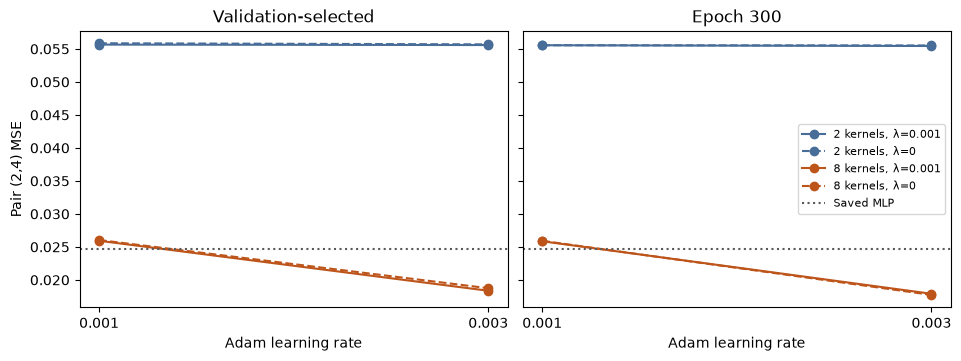

In [29]:
focus_ablation = {}
for endpoint in ABLATION_ENDPOINTS:
    for row in ablation_rows:
        if row["seed"] == 3307 and row["endpoint"] == endpoint:
            setting = tuple(row[key] for key in factor_fields)
            focus_ablation.setdefault((endpoint, setting), []).append(row)

def mean_at(endpoint, setting, metric):
    return average(focus_ablation[endpoint, setting], metric)

settings_3307 = sorted(setting for endpoint, setting in focus_ablation if endpoint == "selected")
table(["Kernels", "Rate", "λ", *(f"Selected pair MSE, init {s}" for s in c.INIT_SEEDS),
       "Selected mean pair MSE", "Epoch 300 mean pair MSE", "Selected signal MSE", "Selected test RMSE",
       "Pair above cutoff"],
      [(*setting, *(f"{r['pair_mse']:.5f}" for r in focus_ablation["selected", setting]),
        f"{mean_at('selected', setting, 'pair_mse'):.5f}", f"{mean_at('epoch_300', setting, 'pair_mse'):.5f}",
        f"{mean_at('selected', setting, 'signal_mse'):.5f}", f"{mean_at('selected', setting, 'test_rmse'):.5f}",
        f"{sum(r['pair_score'] > r['selection_cutoff'] for r in focus_ablation['selected', setting])}/3")
       for setting in settings_3307])

mlp_reference = diagnostic_groups["Second sparse • seed 3307"]["mlp"]["pair_mse"][(2, 4)]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5), sharey=True, layout="constrained")
for ax, endpoint in zip(axes, ABLATION_ENDPOINTS):
    for kernels, color in ((2, "#486d98"), (8, "#bd541a")):
        for penalty, linestyle in ((0.001, "-"), (0., "--")):
            values = [mean_at(endpoint, (kernels, rate, penalty), "pair_mse") for rate in (0.001, 0.003)]
            ax.plot([0, 1], values, marker="o", linestyle=linestyle, color=color, label=f"{kernels} kernels, λ={penalty:g}")
    ax.axhline(mlp_reference, color="0.35", linestyle=":", label="Saved MLP")
    ax.set(title=endpoint_labels[endpoint], xlabel="Adam learning rate", xticks=[0, 1], xticklabels=["0.001", "0.003"])
axes[0].set_ylabel("Pair (2,4) MSE")
axes[1].legend(fontsize=8, loc="best")
plt.show()

## What the controlled fits establish

Use one-factor changes from the original settings to anchor the interpretation, then compare across the full grid. The lowest observed cell is retrospective and carries no new test-selection claim.

In [30]:
baseline_shape = mean_at("selected", ABLATION_BASELINE, "pair_mse")
effect_lines = []
for label, field, original, alternate in ablation_factors:
    altered = list(ABLATION_BASELINE)
    altered[factor_fields.index(field)] = alternate
    altered = tuple(altered)
    one = mean_at("selected", altered, "pair_mse") - baseline_shape
    selected = effect_values["selected", "Seed 3307", field]
    fixed = effect_values["epoch_300", "Seed 3307", field]
    effect_lines.append(f"{label} changed selected pair MSE by {one:+.5f} with other settings at baseline. "
                        f"Across the other settings, the matched mean was {selected:+.5f} at validation selection "
                        f"and {fixed:+.5f} at epoch 300.")

best_shape = min(settings_3307, key=lambda setting: mean_at("selected", setting, "pair_mse"))
shape_value = mean_at("selected", best_shape, "pair_mse")
test_base = mean_at("selected", ABLATION_BASELINE, "test_rmse")
test_shape = mean_at("selected", best_shape, "test_rmse")
mlp_test_ref = average([row for row in focus_fits if row["model"] == "mlp"], "noisy_test_rmse")
display(Markdown(f"""
**Seed 3307.** The reproduced baseline pair MSE was {baseline_shape:.5f}.

{' '.join(effect_lines)}

The lowest observed pair MSE was {shape_value:.5f} with {best_shape[0]} kernels,
learning rate {best_shape[1]:g}, and λ={best_shape[2]:g}. The saved MLP reference had
pair MSE {mlp_reference:.5f}. At this same MGS-KAN setting, whole-model test RMSE was
{test_shape:.5f} versus {test_base:.5f} at baseline and {mlp_test_ref:.5f} for the saved MLP.

**Scope.** The results isolate these settings within a targeted intervention on one planted
pair, using three previously studied splits. The lowest observed setting would need a new
evaluation on fresh splits to support a general prediction claim.
"""))


**Seed 3307.** The reproduced baseline pair MSE was 0.05565.

Kernels 2 → 8 changed selected pair MSE by -0.02973 with other settings at baseline. Across the other settings, the matched mean was -0.03343 at validation selection and -0.03367 at epoch 300. LR 0.001 → 0.003 changed selected pair MSE by -0.00007 with other settings at baseline. Across the other settings, the matched mean was -0.00378 at validation selection and -0.00407 at epoch 300. Penalty 0.001 → 0 changed selected pair MSE by +0.00021 with other settings at baseline. Across the other settings, the matched mean was +0.00020 at validation selection and -0.00000 at epoch 300.

The lowest observed pair MSE was 0.01836 with 8 kernels,
learning rate 0.003, and λ=0.001. The saved MLP reference had
pair MSE 0.02468. At this same MGS-KAN setting, whole-model test RMSE was
0.19236 versus 0.28831 at baseline and 0.27392 for the saved MLP.

**Scope.** The results isolate these settings within a targeted intervention on one planted
pair, using three previously studied splits. The lowest observed setting would need a new
evaluation on fresh splits to support a general prediction claim.


# Fresh-seed test of the 8-kernel setting

Compare the fixed expansion against the original two-kernel MGS-KAN and the MLP on the **second sparse target only**. Use ten new data seeds, 4101 through 4110, with three original initialization seeds per split. This gives **90 fits**. Every arm uses the same split rows, train-fitted scaler, and minibatch order within each data and initialization seed. The two KAN arms share their starting predictor.

| Arm | Kernels on (2,4) | Learning rate | Regularization | Parameters |
| --- | ---: | ---: | --- | ---: |
| Expanded MGS-KAN | 8 | 0.003 | Group penalty $lambda=0.001$ | 985 |
| Original MGS-KAN | 2 | 0.001 | Group penalty $lambda=0.001$ | 949 |
| Original MLP | — | 0.003 | No weight decay | 937 |

Settings come from the preceding studies and are frozen before fitting these splits. The expansion adds only six kernels to the known oscillatory pair. The comparison tests this targeted setting, including its higher learning rate and additional 36 parameters. Checkpoints use the original validation-RMSE rule and patience within 300 epochs. The expanded fitter may continue to epoch 300 after locking the selected checkpoint, whose weights alone are evaluated here.

In [31]:
from experiments.pair_confirmation import DATA_SEEDS as CONFIRMATION_SEEDS
from experiments.pair_confirmation import SETTINGS as CONFIRMATION_SETTINGS
from experiments.pair_confirmation import confirmation_model, run_confirmation

confirmation_output, confirmation_manifest, confirmation_elapsed = run_confirmation(
    output_root / "confirmation", follow_output, follow_protocol, ablation_output,
)
confirmation_fits = list(confirmation_manifest["fits"].values())
assert len(confirmation_fits) == 90
print(f"Verified {len(confirmation_fits)} checkpoints under {confirmation_output}.")
print(f"This execution of the confirmation stage took {confirmation_elapsed:.1f} seconds.")

9/90 fits verified (9 reused)


18/90 fits verified (18 reused)


27/90 fits verified (27 reused)


36/90 fits verified (36 reused)


45/90 fits verified (45 reused)


54/90 fits verified (54 reused)


63/90 fits verified (63 reused)


72/90 fits verified (72 reused)


81/90 fits verified (81 reused)


90/90 fits verified (90 reused)


Verified 90 checkpoints under outputs/study/confirmation/8ef2c0ec02a44237.
This execution of the confirmation stage took 3.5 seconds.


## Pair (2,4) shape error

Measure MSE of the learned pure pair surface against the noiseless $sin(2x_2)sin(2x_4)$ component on independent standard-normal coordinates. As above, subtract both marginal means and add the grand mean. For the MLP, approximate the conditional mean with the same 256 fixed Sobol backgrounds. Use the original 40-node normal quadrature for all arms. This metric is in squared target units. Average the three per-fit pair MSEs within each split before comparing arms.

In [32]:
@torch.inference_mode()
def score_confirmation_pair(fits, output, reference, nodes=40, power=8, scramble=5317):
    axis, weights = axes_normal(nodes)
    background = normal_sobol(c.FEATURES, scramble, power)
    coords = (2, 4)
    grid = torch.cartesian_prod(axis, axis)
    truth = truth_projections("sparse_overlap", reference, axis, weights)[1][coords]
    results = []
    for seed in sorted({r["seed"] for r in fits}):
        feature_seed, _ = np.random.SeedSequence(seed).spawn(2)
        train = np.random.default_rng(feature_seed).standard_normal((c.SPLIT_SIZES[0], c.FEATURES))
        mean, scale = map(torch.from_numpy, (train.mean(axis=0), train.std(axis=0)))
        for fit in (r for r in fits if r["seed"] == seed):
            name, init = fit["model"], fit["init"]
            path = output / fit["artifact"]
            assert sha256(path.read_bytes()).hexdigest() == fit["sha256"]
            saved = torch.load(path, weights_only=True, map_location="cpu")
            model = confirmation_model(name, init).eval()
            model.load_state_dict(saved["checkpoint"], strict=True)
            if name == "mlp":
                surface = conditional_mean(model, grid, coords, background, mean, scale).reshape(nodes, nodes)
            else:
                model.double()
                i, j = coords
                u, v = (axis - mean[i]) / scale[i], (axis - mean[j]) / scale[j]
                index = model.pairs.tolist().index(list(coords))
                surface = model.pair_values(u[:, None], v[None, :], index)
            error = center(surface, weights) - truth
            mse = (weights @ error.square() @ weights).item()
            assert np.isfinite(mse) and mse >= 0
            results.append({**fit, "pair_mse": mse})
    return results

confirmation_pair_rows = score_confirmation_pair(
    confirmation_fits, confirmation_output, follow_protocol["reference"],
)
assert len(confirmation_pair_rows) == 90

In [33]:
confirmation_labels = {
    "mgs_8": "Expanded MGS-KAN", "mgs_kan": "Original MGS-KAN", "mlp": "MLP",
}

def confirmation_seed_values(rows, metric):
    result = {}
    for seed in sorted({r["seed"] for r in rows}):
        result[seed] = {}
        for name in CONFIRMATION_SETTINGS:
            group = [r for r in rows if (r["seed"], r["model"]) == (seed, name)]
            assert sorted(r["init"] for r in group) == sorted(c.INIT_SEEDS)
            result[seed][name] = average(group, metric)
    return result

def confirmation_report(seed_values, metric):
    names = tuple(CONFIRMATION_SETTINGS)
    means = {name: np.mean([row[name] for row in seed_values.values()]) for name in names}
    deltas = {
        name: np.array([row["mgs_8"] - row[name] for row in seed_values.values()])
        for name in names[1:]
    }
    table(["Arm", f"Mean {metric}"], [(confirmation_labels[name], f"{means[name]:.5f}") for name in names])
    table(["Expanded minus reference", "Mean difference", "Range across seeds", "Seeds favoring expansion"],
          [(confirmation_labels[name], f"{d.mean():+.5f}", f"{d.min():+.5f} to {d.max():+.5f}",
            f"{sum(d < 0)}/{len(d)}") for name, d in deltas.items()])
    table(["Data seed", *(confirmation_labels[name] for name in names)],
          [(seed, *(f"{row[name]:.5f}" for name in names)) for seed, row in seed_values.items()])
    return means, deltas

confirmation_pair = confirmation_seed_values(confirmation_pair_rows, "pair_mse")
pair_means, pair_deltas = confirmation_report(confirmation_pair, "pair (2,4) MSE")

| Arm | Mean pair (2,4) MSE |
| --- | --- |
| Expanded MGS-KAN | 0.01533 |
| Original MGS-KAN | 0.05212 |
| MLP | 0.03182 |

| Expanded minus reference | Mean difference | Range across seeds | Seeds favoring expansion |
| --- | --- | --- | --- |
| Original MGS-KAN | -0.03679 | -0.04448 to -0.03006 | 10/10 |
| MLP | -0.01649 | -0.03629 to -0.00146 | 10/10 |

| Data seed | Expanded MGS-KAN | Original MGS-KAN | MLP |
| --- | --- | --- | --- |
| 4101 | 0.02328 | 0.05585 | 0.02599 |
| 4102 | 0.00597 | 0.05045 | 0.02603 |
| 4103 | 0.02625 | 0.05656 | 0.03125 |
| 4104 | 0.02582 | 0.05587 | 0.02727 |
| 4105 | 0.01105 | 0.05218 | 0.04562 |
| 4106 | 0.01044 | 0.05248 | 0.03457 |
| 4107 | 0.01578 | 0.05080 | 0.02925 |
| 4108 | 0.01138 | 0.05041 | 0.04766 |
| 4109 | 0.00776 | 0.04591 | 0.02569 |
| 4110 | 0.01558 | 0.05071 | 0.02487 |

## Whole-model test RMSE

Test RMSE uses the noisy held-out targets and is in target units. Within each data seed, average each arm's three per-fit RMSEs before computing paired contrasts. The ten data seeds are the independent units.

In [34]:
confirmation_test = confirmation_seed_values(confirmation_fits, "test_rmse")
test_means, test_deltas = confirmation_report(confirmation_test, "test RMSE")

| Arm | Mean test RMSE |
| --- | --- |
| Expanded MGS-KAN | 0.18931 |
| Original MGS-KAN | 0.28447 |
| MLP | 0.30596 |

| Expanded minus reference | Mean difference | Range across seeds | Seeds favoring expansion |
| --- | --- | --- | --- |
| Original MGS-KAN | -0.09516 | -0.12342 to -0.07350 | 10/10 |
| MLP | -0.11665 | -0.16117 to -0.07843 | 10/10 |

| Data seed | Expanded MGS-KAN | Original MGS-KAN | MLP |
| --- | --- | --- | --- |
| 4101 | 0.20491 | 0.28301 | 0.29123 |
| 4102 | 0.15623 | 0.27965 | 0.30362 |
| 4103 | 0.23171 | 0.30521 | 0.31014 |
| 4104 | 0.20455 | 0.28242 | 0.28777 |
| 4105 | 0.17991 | 0.28851 | 0.32995 |
| 4106 | 0.18192 | 0.27974 | 0.30584 |
| 4107 | 0.18909 | 0.28679 | 0.30979 |
| 4108 | 0.18205 | 0.28858 | 0.34322 |
| 4109 | 0.17132 | 0.27498 | 0.30249 |
| 4110 | 0.19140 | 0.27577 | 0.27553 |

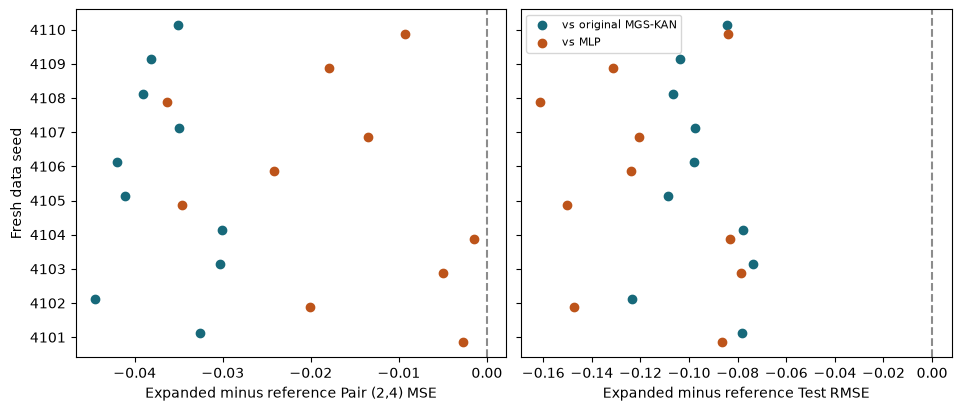

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4), sharey=True, layout="constrained")
for ax, differences, label in zip(axes, (pair_deltas, test_deltas), ("Pair (2,4) MSE", "Test RMSE")):
    y = np.arange(len(CONFIRMATION_SEEDS))
    ax.axvline(0, color="0.55", linestyle="--")
    ax.scatter(differences["mgs_kan"], y + 0.13, color="#17697a", label="vs original MGS-KAN")
    ax.scatter(differences["mlp"], y - 0.13, color="#bd541a", label="vs MLP")
    ax.set(yticks=y, yticklabels=CONFIRMATION_SEEDS, xlabel=f"Expanded minus reference {label}")
axes[0].set_ylabel("Fresh data seed")
axes[1].legend(loc="best", fontsize=8)
plt.show()

## Numerical sensitivity and fresh-seed verdict

Recompute pair error for the first, middle and last seeds by index (4101, 4105 and 4110), fixed independently of outcomes, with 64 quadrature nodes and 512 backgrounds from a different scramble. Use the 40-node results for the primary comparison.

In [36]:
sensitivity_seeds = CONFIRMATION_SEEDS[0], CONFIRMATION_SEEDS[4], CONFIRMATION_SEEDS[-1]
finer = score_confirmation_pair(
    [r for r in confirmation_fits if r["seed"] in sensitivity_seeds],
    confirmation_output, follow_protocol["reference"], nodes=64, power=9, scramble=5413,
)
higher_resolution = confirmation_seed_values(finer, "pair_mse")
table(["Data seed", "Reference", "40-node expanded minus reference", "64-node expanded minus reference"],
      [(seed, confirmation_labels[name], f"{primary['mgs_8'] - primary[name]:+.5f}",
        f"{fine['mgs_8'] - fine[name]:+.5f}")
       for seed, fine in higher_resolution.items() for primary in [confirmation_pair[seed]]
       for name in ("mgs_kan", "mlp")])

def metric_verdict(means, deltas):
    base, mlp = means["mgs_kan"], means["mlp"]
    return (f"The expansion averaged {means['mgs_8']:.5f}, the original MGS-KAN {base:.5f}, and the MLP {mlp:.5f}. "
            f"Its error was lower on {sum(deltas['mgs_kan'] < 0)}/10 seeds against the original MGS-KAN "
            f"and {sum(deltas['mlp'] < 0)}/10 against the MLP.")

display(Markdown(f"""
**Pair (2,4) error.** {metric_verdict(pair_means, pair_deltas)}

**Whole-model prediction.** {metric_verdict(test_means, test_deltas)}

**Scope.** This checks a frozen, targeted expansion on new samples from the same synthetic
function. How to find an interaction to expand when the planted pair is unknown remains
a separate question.
"""))

| Data seed | Reference | 40-node expanded minus reference | 64-node expanded minus reference |
| --- | --- | --- | --- |
| 4101 | Original MGS-KAN | -0.03257 | -0.03268 |
| 4101 | MLP | -0.00271 | -0.00254 |
| 4105 | Original MGS-KAN | -0.04113 | -0.04112 |
| 4105 | MLP | -0.03457 | -0.03413 |
| 4110 | Original MGS-KAN | -0.03512 | -0.03510 |
| 4110 | MLP | -0.00929 | -0.00835 |


**Pair (2,4) error.** The expansion averaged 0.01533, the original MGS-KAN 0.05212, and the MLP 0.03182. Its error was lower on 10/10 seeds against the original MGS-KAN and 10/10 against the MLP.

**Whole-model prediction.** The expansion averaged 0.18931, the original MGS-KAN 0.28447, and the MLP 0.30596. Its error was lower on 10/10 seeds against the original MGS-KAN and 10/10 against the MLP.

**Scope.** This checks a frozen, targeted expansion on new samples from the same synthetic
function. How to find an interaction to expand when the planted pair is unknown remains
a separate question.


# Comparison on the original Gaussian geometry benchmark

This section is self-contained. Open `study.ipynb` from the project root with `python -m jupyterlab study.ipynb`, restart the kernel, and run this section in order. It uses the executable definitions in `gaussian_kan_geometry_vs_mlp_v2.ipynb` and the saved benchmark records in `gkan_results/main/`.

Each model maps two 2D Gaussian states to one Gaussian. MGS-KAN uses the Flat MLP wrapper's bounded coordinates, arithmetic mean base and decoder. Its 2,515-parameter residual gives each of the ten coordinates three Gaussian kernels and each of the 45 pairs five full-precision Gaussian kernels. Each kernel shares its center and precision across five output amplitudes. The pair group penalty is fixed at 0.001.

Training uses float64, 2,000 Adam updates, batch size 64, gradient-norm clip 5 and validation every 10 updates, including step zero. Checkpoints minimize unpenalized validation W₂². Stage B selects one rate per task using the mean best validation W₂² on data seed 2000 and training seeds 11 and 29. Stage D uses the selected rates on data seeds 3000, 4000 and 5000, with training seeds 11, 29 and 47. Partial runs resume from saved optimizer and batch RNG states.

Test W₂² is the sum of squared Euclidean center error and squared Bures–Wasserstein covariance distance. The components use the benchmark's squared distance units. In the paired table, each data-seed difference uses the mean over the three training seeds. Negative differences favor MGS-KAN. The secondary table includes a same-distribution redraw, the mean-only shift, the covariance-only shift, and both shifts together.

In [1]:
from experiments.geometry_benchmark import freeze_protocol, report, run_checks, run_final, show_tuning, tune

geometry_study = freeze_protocol()
print(geometry_study.output)
print(geometry_study.protocol["runtime"])

outputs/study/geometry_benchmark/1bf2a83d7b3d1e7f
{'torch': '2.15.0+cu132', 'numpy': '2.5.4', 'python': '3.12.16', 'platform': 'Linux-6.18.63-3-lts-x86_64-with-glibc2.44', 'device': 'cuda', 'cpu': 'Intel(R) Core(TM) i5-9400F CPU @ 2.90GHz', 'dtype': 'float64', 'cuda': '13.2', 'device_name': 'NVIDIA GeForce GTX 1660 Ti'}


In [2]:
geometry_checks = run_checks(geometry_study)
print(geometry_checks)

{'passed': True, 'reference_dataset_task_seed_checks': 6, 'batch_indices_checked': 1088, 'reference_flat_geodesic_fixture_w2': 0.07386869616739712, 'trainable_parameters': 2515, 'smoke_updates': 20, 'partial_resume_exact': True, 'archived_replays': 162, 'archive_cpu_replay_max_abs_w2_difference': 3.58046925441613e-15}


In [3]:
geometry_dev, geometry_choice = tune(geometry_study)
assert len({r["key"] for r in geometry_dev}) == 18
show_tuning(geometry_choice)

3/18 Stage B fits verified (0 reused)


6/18 Stage B fits verified (0 reused)


9/18 Stage B fits verified (0 reused)


12/18 Stage B fits verified (0 reused)


15/18 Stage B fits verified (0 reused)


18/18 Stage B fits verified (0 reused)


| Task | Learning rate | Mean best validation W₂² | Selected |
| --- | --- | --- | --- |
| affine | 0.001 | 0.000924608 |  |
| affine | 0.003 | 0.000637899 |  |
| affine | 0.01 | 0.0003761915 | Yes |
| geodesic | 0.001 | 0.002613364 |  |
| geodesic | 0.003 | 0.001591016 |  |
| geodesic | 0.01 | 0.001157837 | Yes |
| nonlinear | 0.001 | 0.008749008 |  |
| nonlinear | 0.003 | 0.006682291 |  |
| nonlinear | 0.01 | 0.005786475 | Yes |

In [4]:
geometry_final = run_final(geometry_study, geometry_choice)
assert len({r["key"] for r in geometry_final}) == 27

3/27 Stage D fits verified (0 reused)


6/27 Stage D fits verified (0 reused)


9/27 Stage D fits verified (0 reused)


12/27 Stage D fits verified (0 reused)


15/27 Stage D fits verified (0 reused)


18/27 Stage D fits verified (0 reused)


21/27 Stage D fits verified (0 reused)


24/27 Stage D fits verified (0 reused)


27/27 Stage D fits verified (0 reused)


In [5]:
report(geometry_study, geometry_final)

### Primary held-out results

| Task | Model | Parameters | Test W₂² | Center | Covariance |
| --- | --- | --- | --- | --- | --- |
| affine | MGS-KAN | 2515 | 0.0005394 | 0.0001056 | 0.0004338 |
| affine | Spline / mean | 2520 | 0.0000340 | 0.0000158 | 0.0000182 |
| affine | MLP edges / mean | 2520 | 0.0000341 | 0.0000318 | 0.0000024 |
| affine | Flat MLP | 2483 | 0.0014799 | 0.0006527 | 0.0008272 |
| affine | Spline / BW | 2520 | 0.0023244 | 0.0000373 | 0.0022870 |
| affine | MLP edges / BW | 2520 | 0.0014889 | 0.0001402 | 0.0013487 |
| affine | Anchor / BW | 162 | 0.0055981 | 0.0009203 | 0.0046778 |
| geodesic | MGS-KAN | 2515 | 0.0016678 | 0.0002697 | 0.0013981 |
| geodesic | Spline / mean | 2520 | 0.0036162 | 0.0007298 | 0.0028864 |
| geodesic | MLP edges / mean | 2520 | 0.0016156 | 0.0006336 | 0.0009820 |
| geodesic | Flat MLP | 2483 | 0.0027978 | 0.0014585 | 0.0013393 |
| geodesic | Spline / BW | 2520 | 0.0009742 | 0.0005378 | 0.0004364 |
| geodesic | MLP edges / BW | 2520 | 0.0005139 | 0.0004895 | 0.0000244 |
| geodesic | Anchor / BW | 162 | 0.0320192 | 0.0243314 | 0.0076879 |
| nonlinear | MGS-KAN | 2515 | 0.0030013 | 0.0009708 | 0.0020305 |
| nonlinear | Spline / mean | 2520 | 0.0437588 | 0.0331686 | 0.0105902 |
| nonlinear | MLP edges / mean | 2520 | 0.0119114 | 0.0061473 | 0.0057641 |
| nonlinear | Flat MLP | 2483 | 0.0051862 | 0.0025184 | 0.0026679 |
| nonlinear | Spline / BW | 2520 | 0.0456257 | 0.0329045 | 0.0127212 |
| nonlinear | MLP edges / BW | 2520 | 0.0155004 | 0.0072693 | 0.0082312 |
| nonlinear | Anchor / BW | 162 | 0.0627390 | 0.0358210 | 0.0269181 |

### Paired W₂² differences

| Task | Comparator | Seed 3000 | Seed 4000 | Seed 5000 | Mean Δ | Center Δ | Covariance Δ |
| --- | --- | --- | --- | --- | --- | --- | --- |
| affine | Flat MLP | -0.0009993 | -0.0008692 | -0.0009529 | -0.0009405 | -0.0005470 | -0.0003934 |
| affine | Spline / mean | +0.0005364 | +0.0004445 | +0.0005353 | +0.0005054 | +0.0000898 | +0.0004156 |
| affine | Spline / BW | -0.0026779 | -0.0010494 | -0.0016277 | -0.0017850 | +0.0000683 | -0.0018533 |
| geodesic | Flat MLP | -0.0014642 | -0.0009484 | -0.0009774 | -0.0011300 | -0.0011888 | +0.0000588 |
| geodesic | Spline / mean | -0.0033857 | -0.0016308 | -0.0008286 | -0.0019484 | -0.0004601 | -0.0014883 |
| geodesic | Spline / BW | +0.0002115 | +0.0003348 | +0.0015346 | +0.0006936 | -0.0002682 | +0.0009618 |
| geodesic | MLP edges / BW | +0.0009590 | +0.0006321 | +0.0018707 | +0.0011539 | -0.0002198 | +0.0013737 |
| nonlinear | Flat MLP | -0.0020639 | -0.0014982 | -0.0029928 | -0.0021850 | -0.0015475 | -0.0006374 |
| nonlinear | Spline / mean | -0.0440511 | -0.0400765 | -0.0381449 | -0.0407575 | -0.0321978 | -0.0085597 |
| nonlinear | Spline / BW | -0.0461035 | -0.0413887 | -0.0403811 | -0.0426244 | -0.0319337 | -0.0106907 |

### Distribution shift

| Task | Model | ID redraw | Mean shift | Covariance shift | Both shifts |
| --- | --- | --- | --- | --- | --- |
| affine | MGS-KAN | 0.0004617 | 0.0084654 | 0.0073990 | 0.0154546 |
| affine | Spline / mean | 0.0000279 | 0.0081286 | 0.0003125 | 0.0098050 |
| affine | MLP edges / mean | 0.0000356 | 0.0051932 | 0.0000754 | 0.0058376 |
| affine | Flat MLP | 0.0013877 | 0.0198452 | 0.0107513 | 0.0323137 |
| affine | Spline / BW | 0.0026484 | 0.0168554 | 0.0549895 | 0.0748039 |
| affine | MLP edges / BW | 0.0015281 | 0.0116001 | 0.0214211 | 0.0351871 |
| affine | Anchor / BW | 0.0055199 | 0.0388442 | 0.0384652 | 0.0874186 |
| geodesic | MGS-KAN | 0.0012246 | 0.0167787 | 0.0216681 | 0.0374322 |
| geodesic | Spline / mean | 0.0033747 | 0.0449795 | 0.0432373 | 0.0943134 |
| geodesic | MLP edges / mean | 0.0013442 | 0.0191074 | 0.0193848 | 0.0409016 |
| geodesic | Flat MLP | 0.0023549 | 0.0316915 | 0.0263114 | 0.0585020 |
| geodesic | Spline / BW | 0.0009791 | 0.0269922 | 0.0154815 | 0.0432534 |
| geodesic | MLP edges / BW | 0.0004337 | 0.0168084 | 0.0009382 | 0.0189407 |
| geodesic | Anchor / BW | 0.0309765 | 0.1239268 | 0.0520535 | 0.1463608 |
| nonlinear | MGS-KAN | 0.0034623 | 0.0676355 | 0.0082487 | 0.0934502 |
| nonlinear | Spline / mean | 0.0438471 | 0.1295348 | 0.0678369 | 0.1766419 |
| nonlinear | MLP edges / mean | 0.0128357 | 0.1142813 | 0.0407376 | 0.1804083 |
| nonlinear | Flat MLP | 0.0057787 | 0.0937230 | 0.0118637 | 0.1211419 |
| nonlinear | Spline / BW | 0.0452322 | 0.1333041 | 0.0938196 | 0.2073374 |
| nonlinear | MLP edges / BW | 0.0159781 | 0.1201598 | 0.0632853 | 0.2095900 |
| nonlinear | Anchor / BW | 0.0616867 | 0.2108822 | 0.1204868 | 0.3116826 |

### Timing

| Model | Recorded device | Timing basis | Mean seconds |
| --- | --- | --- | --- |
| MGS-KAN | NVIDIA GeForce GTX 1660 Ti | per fit | 12.34 |
| Spline / mean | NVIDIA GeForce GTX 1660 Ti | archive, GPU-group amortized | 1.29 |
| MLP edges / mean | NVIDIA GeForce GTX 1660 Ti | archive, GPU-group amortized | 1.16 |
| Flat MLP | NVIDIA GeForce GTX 1660 Ti | archive, GPU-group amortized | 0.51 |
| Spline / BW | NVIDIA GeForce GTX 1660 Ti | archive, GPU-group amortized | 25.16 |
| MLP edges / BW | NVIDIA GeForce GTX 1660 Ti | archive, GPU-group amortized | 24.99 |
| Anchor / BW | NVIDIA GeForce GTX 1660 Ti | archive, GPU-group amortized | 27.96 |

Archived GPU timings are amortized across a batch of independent runs. The new arm was timed per fit on its recorded device. These figures describe the executions separately.

### Verdict

- **Affine** has lower mean W₂² versus Flat MLP (-0.0009405, 3/3 splits favor MGS-KAN). The larger component difference is center (-0.0005470).
- **Geodesic** has lower mean W₂² versus Flat MLP (-0.0011300, 3/3 splits favor MGS-KAN). The larger component difference is center (-0.0011888).
- **Nonlinear** has lower mean W₂² versus Flat MLP (-0.0021850, 3/3 splits favor MGS-KAN). The larger component difference is center (-0.0015475).

The largest absolute Flat MLP gap is on **nonlinear**. All 162 historical and 27 new fits are paired on the original evaluation seeds. This is a paired historical comparison on known seeds. Confirmation on previously unseen seeds is left for a later experiment. The individual-fit table contains unrounded W₂² and its components by split.

Saved individual-fit rows to outputs/study/geometry_benchmark/1bf2a83d7b3d1e7f/individual_fits.csv


**Recorded seven-arm ranking.** MGS-KAN ranked 3/7 on affine, 4/7 on geodesic, 1/7 on nonlinear. Spline / mean led on affine, and MLP edges / BW led on geodesic.

On geodesic, MGS-KAN's covariance error exceeded MLP edges / BW by 0.0013737. Its center error was lower by 0.0002198.

# Fresh-seed confirmation of the seven-model Gaussian geometry benchmark

This section runs independently from a fresh kernel in the project root. It keeps all seven model architectures and each task's previously selected learning rate. The only change to the experimental design is the data seed. Seeds 6000, 7000 and 8000 were disjoint from the earlier geometry training, development and evaluation seeds. All seven models train on each task and data seed with initialization seeds 11, 29 and 47, for 189 new fits.

The original float64 generators, split sizes, matched minibatch RNG, 2,000 Adam updates, gradient clipping, validation schedule and checkpoint selection rule carry forward. MGS-KAN keeps three univariate kernels per coordinate, five bivariate kernels per pair, and a pair group penalty of 0.001. Checkpoint selection and evaluation use unpenalized W₂². This run batches the 27 independent fits per model on CPU. It writes new protocols and resumable checkpoints under `outputs/study/geometry_confirmation/`.

The primary comparison is test W₂², with the squared center and covariance terms shown separately. Each seed-level contrast averages the three initializations first. Negative values favor MGS-KAN. The distribution-shift scores and execution timings appear in separate tables. The three new data seeds provide a paired descriptive comparison.

In [1]:
from experiments.geometry_confirmation import (
    freeze_protocol as freeze_geometry_confirmation,
    report as report_geometry_confirmation,
    run_confirmation as run_geometry_confirmation,
)

geometry_confirmation = freeze_geometry_confirmation()
print(geometry_confirmation.output)
print(geometry_confirmation.protocol["learning_rates"])

outputs/study/geometry_confirmation/21f00c136f3672af
{'MGS-KAN': {'affine': 0.01, 'geodesic': 0.01, 'nonlinear': 0.01}, 'Spline / mean': {'affine': 0.003, 'geodesic': 0.01, 'nonlinear': 0.003}, 'MLP edges / mean': {'affine': 0.01, 'geodesic': 0.01, 'nonlinear': 0.01}, 'Flat MLP': {'affine': 0.003, 'geodesic': 0.001, 'nonlinear': 0.01}, 'Spline / BW': {'affine': 0.01, 'geodesic': 0.01, 'nonlinear': 0.001}, 'MLP edges / BW': {'affine': 0.003, 'geodesic': 0.01, 'nonlinear': 0.01}, 'Anchor / BW': {'affine': 0.01, 'geodesic': 0.01, 'nonlinear': 0.01}}


In [2]:
fresh_geometry_fits = run_geometry_confirmation(geometry_confirmation)
assert len({row["key"] for row in fresh_geometry_fits}) == 189

MGS-KAN: 27/27 verified (27 reused)


Spline / mean: 27/27 verified (27 reused)


MLP edges / mean: 27/27 verified (27 reused)


Flat MLP: 27/27 verified (27 reused)


MLP edges / BW: 27/27 verified (27 reused)


Anchor / BW: 27/27 verified (27 reused)


Spline / BW: 27/27 verified (27 reused)


189/189 confirmation fits verified (189 reused) in 6.6s


In [3]:
report_geometry_confirmation(geometry_confirmation, fresh_geometry_fits)

### Affine

| Model | Parameters | Test W₂² | Center | Covariance |
| --- | --- | --- | --- | --- |
| Spline / mean | 2520 | 0.0000177 | 0.0000050 | 0.0000128 |
| MLP edges / mean | 2520 | 0.0000288 | 0.0000258 | 0.0000030 |
| MGS-KAN | 2515 | 0.0006156 | 0.0000695 | 0.0005460 |
| Flat MLP | 2483 | 0.0014958 | 0.0005452 | 0.0009506 |
| MLP edges / BW | 2520 | 0.0016024 | 0.0001196 | 0.0014828 |
| Spline / BW | 2520 | 0.0023578 | 0.0000479 | 0.0023098 |
| Anchor / BW | 162 | 0.0059902 | 0.0008887 | 0.0051015 |

### Geodesic

| Model | Parameters | Test W₂² | Center | Covariance |
| --- | --- | --- | --- | --- |
| MLP edges / BW | 2520 | 0.0003282 | 0.0003068 | 0.0000214 |
| Spline / BW | 2520 | 0.0011072 | 0.0003988 | 0.0007084 |
| MLP edges / mean | 2520 | 0.0014141 | 0.0004106 | 0.0010035 |
| MGS-KAN | 2515 | 0.0015386 | 0.0002142 | 0.0013245 |
| Flat MLP | 2483 | 0.0025599 | 0.0011812 | 0.0013787 |
| Spline / mean | 2520 | 0.0035697 | 0.0003635 | 0.0032062 |
| Anchor / BW | 162 | 0.0327037 | 0.0248340 | 0.0078697 |

### Nonlinear

| Model | Parameters | Test W₂² | Center | Covariance |
| --- | --- | --- | --- | --- |
| MGS-KAN | 2515 | 0.0034113 | 0.0013467 | 0.0020646 |
| Flat MLP | 2483 | 0.0056751 | 0.0031861 | 0.0024890 |
| MLP edges / mean | 2520 | 0.0124486 | 0.0065080 | 0.0059406 |
| MLP edges / BW | 2520 | 0.0154990 | 0.0070630 | 0.0084360 |
| Spline / mean | 2520 | 0.0450840 | 0.0350390 | 0.0100450 |
| Spline / BW | 2520 | 0.0467395 | 0.0351220 | 0.0116175 |
| Anchor / BW | 162 | 0.0649448 | 0.0399434 | 0.0250014 |

... (3 outputs left out)

| Task | Model | ID redraw | Mean shift | Covariance shift | Both shifts |
| --- | --- | --- | --- | --- | --- |
| affine | MGS-KAN | 0.0005236 | 0.0097890 | 0.0069728 | 0.0163070 |
| affine | Spline / mean | 0.0000254 | 0.0065800 | 0.0003058 | 0.0070701 |
| affine | MLP edges / mean | 0.0000319 | 0.0066742 | 0.0000730 | 0.0072677 |
| affine | Flat MLP | 0.0014745 | 0.0228448 | 0.0098986 | 0.0338845 |
| affine | Spline / BW | 0.0020479 | 0.0168937 | 0.0399707 | 0.0587377 |
| affine | MLP edges / BW | 0.0012274 | 0.0121482 | 0.0217792 | 0.0356366 |
| affine | Anchor / BW | 0.0046403 | 0.0385360 | 0.0341452 | 0.0827696 |
| geodesic | MGS-KAN | 0.0012378 | 0.0186221 | 0.0219921 | 0.0393817 |
| geodesic | Spline / mean | 0.0029306 | 0.0427415 | 0.0463241 | 0.0919595 |
| geodesic | MLP edges / mean | 0.0013174 | 0.0202842 | 0.0194711 | 0.0426227 |
| geodesic | Flat MLP | 0.0026555 | 0.0354241 | 0.0277365 | 0.0631437 |
| geodesic | Spline / BW | 0.0008041 | 0.0391040 | 0.0108181 | 0.0546498 |
| geodesic | MLP edges / BW | 0.0004421 | 0.0177300 | 0.0006972 | 0.0189269 |
| geodesic | Anchor / BW | 0.0335448 | 0.1360479 | 0.0540914 | 0.1588268 |
| nonlinear | MGS-KAN | 0.0035255 | 0.0734250 | 0.0084212 | 0.0956277 |
| nonlinear | Spline / mean | 0.0470799 | 0.1324383 | 0.0677200 | 0.1644587 |
| nonlinear | MLP edges / mean | 0.0131778 | 0.1411859 | 0.0382215 | 0.1989138 |
| nonlinear | Flat MLP | 0.0053678 | 0.1006483 | 0.0120407 | 0.1241662 |
| nonlinear | Spline / BW | 0.0484531 | 0.1344594 | 0.0948750 | 0.1950469 |
| nonlinear | MLP edges / BW | 0.0156520 | 0.1343369 | 0.0680774 | 0.2098053 |
| nonlinear | Anchor / BW | 0.0660767 | 0.1980981 | 0.1215391 | 0.2882960 |

### Timing

| Model | Device | Seconds for group of 27 | Amortized seconds per fit |
| --- | --- | --- | --- |
| MGS-KAN | Intel(R) Core(TM) i5-9400F CPU @ 2.90GHz | 110.94 | 4.11 |
| Spline / mean | Intel(R) Core(TM) i5-9400F CPU @ 2.90GHz | 248.87 | 9.22 |
| MLP edges / mean | Intel(R) Core(TM) i5-9400F CPU @ 2.90GHz | 90.02 | 3.33 |
| Flat MLP | Intel(R) Core(TM) i5-9400F CPU @ 2.90GHz | 27.74 | 1.03 |
| Spline / BW | Intel(R) Core(TM) i5-9400F CPU @ 2.90GHz | 742.87 | 27.51 |
| MLP edges / BW | Intel(R) Core(TM) i5-9400F CPU @ 2.90GHz | 641.69 | 23.77 |
| Anchor / BW | Intel(R) Core(TM) i5-9400F CPU @ 2.90GHz | 723.84 | 26.81 |

### Fresh-seed verdict

- **Affine** ranks 3/7 for MGS-KAN. Spline / mean leads. MGS-KAN has lower W₂² than Flat MLP on 3/3 splits (mean difference -0.0008802).
- **Geodesic** ranks 4/7 for MGS-KAN. MLP edges / BW leads. MGS-KAN has lower W₂² than Flat MLP on 3/3 splits (mean difference -0.0010213).
- **Nonlinear** ranks 1/7 for MGS-KAN. MGS-KAN leads. MGS-KAN has lower W₂² than Flat MLP on 3/3 splits (mean difference -0.0022638).

Each comparison averages the three training initializations within each fresh data seed. CPU groups were trained concurrently. Historical GPU timings remain in the preceding section.

### Comparison with the original run

The task-level ranking replicated on the new data. Spline / mean again led on affine, MLP edges / BW again led on geodesic, and MGS-KAN again led on nonlinear. On nonlinear, MGS-KAN beat every comparator on each of the three fresh data seeds. Its mean W₂² was 0.0034113 versus 0.0056751 for the runner-up, Flat MLP.

The geodesic gap against MLP edges / BW was +0.0012105 W₂². Its covariance contribution was +0.0013031 and its center contribution was −0.0000926. The geodesic comparisons against Spline / BW and MLP edges / mean changed direction by seed. MGS-KAN won both comparisons on 6000 and lost both on 7000 and 8000.

The completing CPU invocation took 753 seconds after resuming two partially trained model groups. All 189 selected checkpoints reloaded. An independent reconstruction from the saved Gaussian means and covariances matched all 1,323 split scores and their components to within 3.61 × 10⁻¹⁶. Two fresh Jupyter kernels reproduced the same report tables. The three fresh data seeds support a descriptive comparison.

[Run manifest](outputs/study/geometry_confirmation/21f00c136f3672af/manifest.json) · [Individual fits](outputs/study/geometry_confirmation/21f00c136f3672af/individual_fits.csv) · [Paired differences](outputs/study/geometry_confirmation/21f00c136f3672af/paired_differences.csv)